<a href="https://colab.research.google.com/github/DataScience-Fatec-Projects/kmeans-musicas-spotify/blob/main/notebooks/aula_kmeans_spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula: K-Means em Ciência de Dados — agrupando músicas do Spotify

**Disciplina:** ICD-004 Análise de Algoritmos · Fatec Jundiaí
**Professor:** Prof. Humberto Zanetti
**Data:** 24/11/2026

**Integrantes:**
- Wellington Junior Torres de Melo
<!-- Novos integrantes: acrescente uma linha "- Nome completo" acima. -->

**Repositório:** [github.com/DataScience-Fatec-Projects/kmeans-musicas-spotify](https://github.com/DataScience-Fatec-Projects/kmeans-musicas-spotify)

> Como usar esta aula: leia de cima para baixo e execute as células em ordem
> (*Ambiente de execução → Executar tudo*). As células **🧪 Experimente** convidam você a mudar
> um parâmetro e rodar de novo.

## Sumário

- [⚙️ Configuração do ambiente](#⚙️-Configuração-do-ambiente)
- [I. Introdução e Contextualização](#I.-Introdução-e-Contextualização)
  - [I.1 Aprendizado não supervisionado](#I.1-Aprendizado-não-supervisionado)
  - [I.2 Clustering (agrupamento)](#I.2-Clustering-(agrupamento))
  - [I.3 Como o K-Means funciona — implementado do zero](#I.3-Como-o-K-Means-funciona-—-implementado-do-zero)
  - [I.4 Quanto custa? Complexidade do K-Means](#I.4-Quanto-custa?-Complexidade-do-K-Means)
  - [I.5 Como avaliar: inércia, Método do Cotovelo e silhueta](#I.5-Como-avaliar:-inércia,-Método-do-Cotovelo-e-silhueta)
- [II. Ferramentas de Trabalho (Scikit-learn e Python)](#II.-Ferramentas-de-Trabalho-(Scikit-learn-e-Python))
  - [II.1 Bibliotecas e importações](#II.1-Bibliotecas-e-importações)
  - [II.2 O KMeans do scikit-learn](#II.2-O-KMeans-do-scikit-learn)
- [III. Escolha do Tema e Preparação dos Dados](#III.-Escolha-do-Tema-e-Preparação-dos-Dados)
  - [III.1 Tema: por que agrupar músicas?](#III.1-Tema:-por-que-agrupar-músicas?)
  - [III.2 O dataset: origem e dicionário de variáveis](#III.2-O-dataset:-origem-e-dicionário-de-variáveis)
  - [III.3 Carregamento e limpeza](#III.3-Carregamento-e-limpeza)
  - [III.4 Escolha das features](#III.4-Escolha-das-features)
  - [III.5 Padronização com StandardScaler](#III.5-Padronização-com-StandardScaler)
- [IV. Implementação e Aplicação Prática](#IV.-Implementação-e-Aplicação-Prática)
  - [IV.1 Definindo k: Método do Cotovelo (e silhueta)](#IV.1-Definindo-k:-Método-do-Cotovelo-(e-silhueta))
  - [IV.2 Treinando o K-Means](#IV.2-Treinando-o-K-Means)
  - [IV.3 Visualizando a separação dos clusters](#IV.3-Visualizando-a-separação-dos-clusters)
  - [IV.4 Centroides em relação aos pontos](#IV.4-Centroides-em-relação-aos-pontos)
- [V. Análise e conclusão](#V.-Análise-e-conclusão)
  - [V.1 Perfil de cada cluster](#V.1-Perfil-de-cada-cluster)
  - [V.2 Dando nome aos grupos](#V.2-Dando-nome-aos-grupos)
  - [V.3 Clusters × gêneros (com destaque para a música brasileira)](#V.3-Clusters-×-gêneros-(com-destaque-para-a-música-brasileira))
  - [V.4 Limitações e melhorias](#V.4-Limitações-e-melhorias)
- [Referências](#Referências)

> No Colab, o painel **Índice** (ícone ☰ à esquerda) também mostra esta estrutura.

## ⚙️ Configuração do ambiente

Esta célula prepara tudo o que o resto da aula usa. Ela fica aqui no começo, e não na Seção II,
porque a Seção I já desenha gráficos e roda um K-Means de exemplo. A Seção II explica cada
biblioteca com calma.

O que ela faz:

1. **Importa as bibliotecas**: `numpy` e `pandas` (dados), `matplotlib` e `seaborn` (gráficos) e
   as partes do `scikit-learn` usadas na aula (padronização, K-Means, métricas, PCA e dados de
   exemplo; a PCA é explicada na IV.4).
2. **Fixa a semente aleatória** `RANDOM_STATE = 42`. O K-Means e as amostragens sorteiam números;
   com a mesma semente, quem rodar a aula de novo vê **exatamente** os mesmos resultados.
3. **Define as constantes da análise**: o endereço do *dataset* (o conjunto de dados) e o de uma
   cópia de reserva, as 9 *features* (características) de áudio usadas no agrupamento, os gêneros
   que vamos destacar e o tamanho das amostras usadas nas partes mais caras (silhueta, explicada na
   I.5, e gráficos de dispersão).
4. **Escolhe o estilo dos gráficos** e **imprime as versões** do Python e das bibliotecas, para
   que dê para comparar se algum resultado sair diferente.

In [1]:
import json
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from IPython.display import HTML, display

# Semente única de toda a aula (constituição IV): não crie outra.
RANDOM_STATE = 42

# Dataset público no Hugging Face (lido direto da internet, sem upload).
URL_DATASET = (
    "https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset"
    "/resolve/main/dataset.csv"
)
# Cópia idêntica guardada no repositório do projeto, usada só se o Hugging Face falhar.
URL_DATASET_RESERVA = (
    "https://raw.githubusercontent.com/DataScience-Fatec-Projects/kmeans-musicas-spotify"
    "/main/data/spotify_tracks.csv"
)

# As 9 features contínuas de áudio que entram no K-Means (FR-035).
FEATURES = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
]

# Gêneros em destaque na Seção V (FR-034) e gêneros internacionais de contraste.
GENEROS_BR = ["brazil", "mpb", "sertanejo", "pagode", "samba", "forro", "funk"]
GENEROS_CONTRASTE = ["classical", "metal", "sleep", "hip-hop", "edm", "comedy"]

# Amostras para as etapas caras (research R3).
TAMANHO_AMOSTRA_SILHUETA = 10_000  # a silhueta exata é O(n²)
TAMANHO_AMOSTRA_GRAFICOS = 6_000   # dispersão legível, sem virar um borrão

# Estilo padrão dos gráficos.
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 100, "axes.titleweight": "bold"})

print(f"Python       {sys.version.split()[0]}")
for nome, modulo in [("pandas", pd), ("numpy", np), ("scikit-learn", sklearn),
                     ("matplotlib", matplotlib), ("seaborn", sns)]:
    print(f"{nome:<12} {modulo.__version__}")

Python       3.12.13
pandas       3.1.1
numpy        2.5.5
scikit-learn 1.9.1
matplotlib   3.11.2
seaborn      0.13.2


Acima estão as versões usadas nesta execução. No Colab elas mudam de tempos em tempos; se algum
número da aula sair um pouco diferente do texto, compare primeiro estas versões.

## I. Introdução e Contextualização

### I.1 Aprendizado não supervisionado

**Aprendizado de máquina** (*machine learning*) é fazer o computador aprender padrões a partir de
exemplos, em vez de seguir regras escritas à mão. Ele se divide em dois grandes tipos, e a
diferença está nas **respostas** que damos junto com os dados.

**Aprendizado supervisionado**: cada exemplo vem com a resposta certa (o **rótulo**), e o modelo
aprende a prever essa resposta para exemplos novos. É como estudar com um gabarito.

- e-mails marcados como "spam" ou "não spam" → o modelo aprende a filtrar e-mails novos;
- fotos de animais com o nome do animal → o modelo aprende a reconhecer gatos e cachorros;
- casas com o preço de venda → o modelo aprende a estimar o preço de outras casas.

**Aprendizado não supervisionado**: os exemplos **não têm resposta**. Ninguém diz ao modelo o que
procurar; ele precisa descobrir sozinho a estrutura escondida nos dados. É como receber uma caixa
de fotos misturadas e organizá-las sem nenhuma instrução.

| | Supervisionado | Não supervisionado |
|---|---|---|
| Os dados têm rótulo (resposta)? | sim | não |
| Objetivo | prever o rótulo de exemplos novos | descobrir padrões e grupos |
| Como saber se acertou? | comparando com as respostas | interpretando o resultado |
| Exemplo nesta aula | — | agrupar músicas só pelo som |

O caso das músicas é não supervisionado: o Spotify mediu como cada faixa **soa**, mas não existe
uma resposta dizendo a que grupo de som cada uma pertence.

### I.2 Clustering (agrupamento)

**Clustering** (agrupamento) é a tarefa não supervisionada mais comum: dividir os dados em
**grupos** (*clusters*) de forma que os itens de um mesmo grupo sejam **parecidos entre si** e
**diferentes** dos itens dos outros grupos. "Parecido" quase sempre quer dizer **perto**: cada item
vira um ponto num espaço com uma dimensão por característica, e itens próximos são semelhantes.

Exemplos do dia a dia:

- **playlists automáticas**: juntar músicas com o mesmo "clima" (é o que fazemos nesta aula);
- **segmentação de clientes**: uma loja agrupa clientes pelo jeito de comprar, para fazer ofertas
  diferentes para cada grupo;
- **organizar notícias**: juntar textos que falam do mesmo assunto;
- **biologia**: agrupar espécies de flores ou genes com comportamento parecido.

Para ver a ideia, vamos criar um conjunto pequeno de pontos de brinquedo, com 2 características
(eixos x e y), usando `make_blobs` do scikit-learn, que sorteia pontos em torno de alguns centros.
Ele será usado em toda a Seção I.

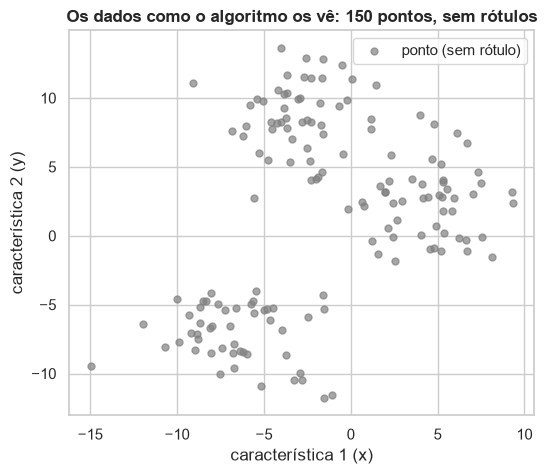

In [2]:
X_brinquedo, _ = make_blobs(n_samples=150, centers=3, cluster_std=2.5, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_brinquedo[:, 0], X_brinquedo[:, 1], s=25, color="gray", alpha=0.7, label="ponto (sem rótulo)")
ax.set(title="Os dados como o algoritmo os vê: 150 pontos, sem rótulos",
       xlabel="característica 1 (x)", ylabel="característica 2 (y)")
ax.legend()
plt.show()

É assim que um algoritmo de agrupamento recebe os dados: só pontos, **sem cores e sem respostas**.
Olhando, dá para suspeitar de três grupos, mas as bordas se misturam no meio. (O `make_blobs`
também devolve o grupo verdadeiro de cada ponto; descartamos essa informação com o `_`, porque num
problema real ela não existe.) O trabalho do K-Means é encontrar esses grupos.

### I.3 Como o K-Means funciona — implementado do zero

O **K-Means** divide os dados em **k** grupos, e cada grupo é representado por um **centroide**:
o ponto médio do grupo. Ele repete quatro passos:

1. **Inicialização**: escolhe k pontos dos dados, ao acaso, como centroides iniciais.
2. **Atribuição**: cada ponto vai para o grupo do centroide **mais próximo** (pela distância
   euclidiana, a "distância em linha reta").
3. **Atualização**: cada centroide passa para a **média** dos pontos do seu grupo.
4. **Critério de parada**: se os centroides praticamente não se mexeram (deslocamento menor que uma
   tolerância `tol`) ou se chegou ao número máximo de iterações (`max_iter`), para. Senão, volta ao
   passo 2.

Cada repetição de atribuição + atualização é uma **iteração**. A função abaixo implementa esses
passos com numpy, em poucas linhas. Cada comentário indica o passo correspondente. Ela devolve os
rótulos finais, os centroides finais, os centroides iniciais, o número de iterações e o histórico
de cada iteração (para desenharmos o passo a passo). O parâmetro opcional `contador` só é usado na
I.4: a cada iteração, ele soma quantas distâncias a função acabou de calcular.

In [3]:
def kmeans_do_zero(X, k, semente, max_iter=100, tol=1e-4, contador=None):
    """K-Means "na mão", com os 4 passos do algoritmo."""
    gerador = np.random.default_rng(semente)
    # 1. Inicialização: k pontos dos dados, sorteados, viram os centroides iniciais
    centroides = X[gerador.choice(len(X), size=k, replace=False)]
    centroides_iniciais = centroides.copy()
    historico = []
    for iteracao in range(1, max_iter + 1):
        # 2. Atribuição: distância de cada ponto a cada centroide (matriz n × k) → o mais próximo
        distancias = np.linalg.norm(X[:, np.newaxis, :] - centroides[np.newaxis, :, :], axis=2)
        rotulos = distancias.argmin(axis=1)
        if contador is not None:  # usado só na I.4, para contar o trabalho feito
            contador["distâncias"] += distancias.size
        # 3. Atualização: cada centroide vai para a média dos pontos do seu grupo
        novos = np.array([X[rotulos == j].mean(axis=0) for j in range(k)])
        historico.append((rotulos, centroides, novos))
        # 4. Parada: o maior deslocamento de um centroide ficou menor que a tolerância
        deslocamento = np.linalg.norm(novos - centroides, axis=1).max()
        centroides = novos
        if deslocamento < tol:
            break
    return rotulos, centroides, centroides_iniciais, iteracao, historico


rotulos_zero, centroides_zero, centroides_iniciais, n_iteracoes, historico = kmeans_do_zero(
    X_brinquedo, k=3, semente=RANDOM_STATE)
print(f"Convergiu em {n_iteracoes} iterações")
print("Centroides finais:")
print(np.round(centroides_zero, 2))

Convergiu em 4 iterações
Centroides finais:
[[-3.04  8.62]
 [-6.59 -7.1 ]
 [ 4.5   2.4 ]]


O algoritmo convergiu em poucas iterações. Os gráficos abaixo mostram cada uma: as cores são a
**atribuição** daquela iteração, o "○" é o centroide antes da atualização, o "X" é o centroide
depois, e a seta mostra o caminho entre os dois.

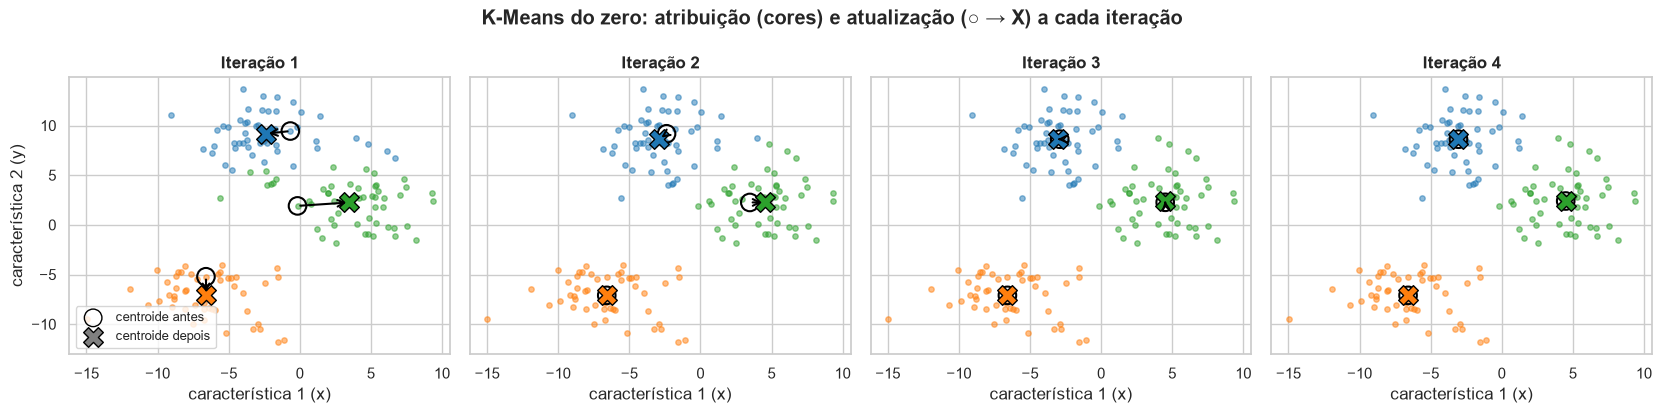

In [4]:
cores_brinquedo = sns.color_palette("tab10", 3)
fig, eixos = plt.subplots(1, len(historico), figsize=(4.2 * len(historico), 4.2), sharex=True, sharey=True)
for i, (ax, (rot, antes, depois)) in enumerate(zip(np.atleast_1d(eixos), historico), start=1):
    for j in range(3):
        ax.scatter(*X_brinquedo[rot == j].T, s=15, alpha=0.5, color=cores_brinquedo[j])
        ax.scatter(*antes[j], s=160, facecolors="none", edgecolors="black", linewidths=1.5)
        ax.scatter(*depois[j], marker="X", s=200, color=cores_brinquedo[j], edgecolor="black", zorder=3)
        ax.annotate("", xy=depois[j], xytext=antes[j], arrowprops=dict(arrowstyle="->", lw=1.5, color="black"))
    ax.set(title=f"Iteração {i}", xlabel="característica 1 (x)")
eixos[0].set_ylabel("característica 2 (y)")
eixos[0].scatter([], [], s=160, facecolors="none", edgecolors="black", label="centroide antes")
eixos[0].scatter([], [], marker="X", s=200, color="gray", edgecolor="black", label="centroide depois")
eixos[0].legend(loc="lower left", fontsize=9)
fig.suptitle("K-Means do zero: atribuição (cores) e atualização (○ → X) a cada iteração",
             fontweight="bold")
plt.tight_layout()
plt.show()

- Na **iteração 1**, os centroides iniciais (○) são 3 pontos sorteados, e as setas são as mais
  longas: cada centroide dá um salto grande em direção ao "meio" do seu grupo.
- Nas iterações seguintes, as setas encolhem. Alguns pontos da fronteira trocam de cor, porque o
  centroide mais próximo deles mudou.
- Na **última iteração**, ○ e X coincidem: os centroides pararam de se mexer (deslocamento menor que
  `tol`) e o algoritmo **convergiu**. Essa última iteração é justamente a que confirma a parada.

**Comparando com o scikit-learn.** O `KMeans` do scikit-learn faz a mesma conta, só que otimizada.
Para comparar de forma justa, ele precisa partir **dos mesmos centroides iniciais**: passamos
`init=centroides_iniciais` e `n_init=1` (uma única inicialização). Com outra inicialização, ele
poderia chegar a outro resultado, como veremos no Experimente abaixo.

Mas como comparar os rótulos? A numeração dos grupos é **arbitrária**: o grupo que uma
implementação chama de 0 pode ser o grupo 2 da outra. Por isso usamos o **ARI** (*Adjusted Rand
Index*), que olha só **quais pontos ficaram juntos**, ignorando os números: ARI = 1 quer dizer
agrupamentos idênticos; ARI ≈ 0, tão parecidos quanto dois agrupamentos sorteados ao acaso.

In [5]:
modelo_sklearn = KMeans(n_clusters=3, init=centroides_iniciais, n_init=1).fit(X_brinquedo)
ari_brinquedo = adjusted_rand_score(rotulos_zero, modelo_sklearn.labels_)
print(f"Iterações: do zero = {n_iteracoes} | scikit-learn = {modelo_sklearn.n_iter_}")
print(f"ARI entre as duas implementações: {ari_brinquedo:.3f}")
print("Maior diferença entre os centroides finais:",
      f"{np.abs(np.sort(centroides_zero, axis=0) - np.sort(modelo_sklearn.cluster_centers_, axis=0)).max():.2e}")

Iterações: do zero = 4 | scikit-learn = 4
ARI entre as duas implementações: 1.000
Maior diferença entre os centroides finais: 2.66e-15


**ARI = 1,000**: partindo dos mesmos centroides, a implementação do zero e a do scikit-learn chegam
exatamente ao mesmo agrupamento, no mesmo número de iterações, e os centroides finais coincidem (a
diferença fica na casa dos arredondamentos do computador). A nossa função de poucas linhas é o
K-Means de verdade.

#### 🧪 Experimente: k e semente do exemplo de brinquedo

A inicialização é **sorteada**, e o resultado depende dela. Mude `SEMENTE_INICIAL` (o sorteio dos
centroides iniciais) e `K_BRINQUEDO` (o número de grupos) e rode de novo:

- Com o valor inicial `SEMENTE_INICIAL = 0`, o algoritmo cai num **mínimo local**: uma solução
  "estável" (os centroides param de se mexer), mas pior que a melhor possível. Compare a inércia com
  a da semente 42, usada acima. (Inércia é a soma das distâncias² até os centroides, explicada na
  I.5: quanto menor, melhor.)
- Tente as sementes 4, 7 ou 14: elas chegam à boa solução, em 4, 5 e 3 iterações.
- Mude `K_BRINQUEDO` para 2 ou 5 e veja como os grupos se ajustam.

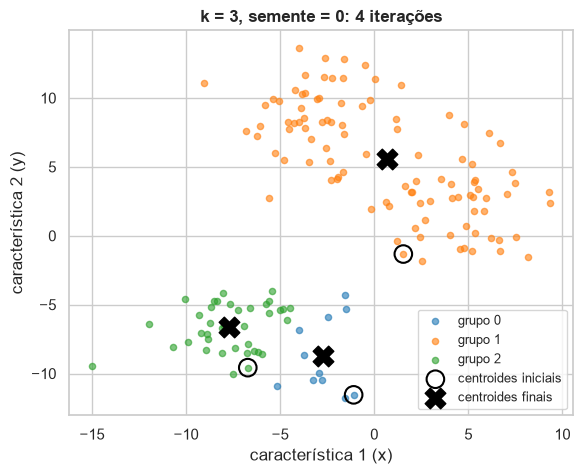

Inércia: 3882.2 (referência acima, k = 3 e semente 42: 1718.2)


In [6]:
K_BRINQUEDO = 3       # ✏️ número de grupos
SEMENTE_INICIAL = 0   # ✏️ sorteio dos centroides iniciais

rot_exp, cent_exp, ini_exp, it_exp, _ = kmeans_do_zero(X_brinquedo, K_BRINQUEDO, SEMENTE_INICIAL)
inercia_exp = sum(((X_brinquedo[rot_exp == j] - cent_exp[j]) ** 2).sum() for j in range(K_BRINQUEDO))
inercia_ref = sum(((X_brinquedo[rotulos_zero == j] - centroides_zero[j]) ** 2).sum() for j in range(3))

cores_exp = sns.color_palette("tab10", K_BRINQUEDO)
fig, ax = plt.subplots(figsize=(6.5, 5))
for j in range(K_BRINQUEDO):
    ax.scatter(*X_brinquedo[rot_exp == j].T, s=20, alpha=0.6, color=cores_exp[j], label=f"grupo {j}")
ax.scatter(*ini_exp.T, s=160, facecolors="none", edgecolors="black", linewidths=1.5, label="centroides iniciais")
ax.scatter(*cent_exp.T, marker="X", s=220, color="black", label="centroides finais")
ax.set(title=f"k = {K_BRINQUEDO}, semente = {SEMENTE_INICIAL}: {it_exp} iterações",
       xlabel="característica 1 (x)", ylabel="característica 2 (y)")
ax.legend(fontsize=9)
plt.show()
print(f"Inércia: {inercia_exp:.1f} (referência acima, k = 3 e semente 42: {inercia_ref:.1f})")

Com os valores iniciais (k = 3, semente 0), dois centroides iniciais caem no mesmo grupo
verdadeiro. O algoritmo então divide esse grupo em dois e junta os outros dois grupos num só: a
inércia fica **bem maior** que a da referência. É por isso que o scikit-learn usa, por padrão, a
inicialização **k-means++** (que espalha os centroides iniciais) e **várias inicializações**
(`n_init`), ficando com a melhor. Veremos isso na II.2.

#### Simulador: o K-Means passo a passo

Os gráficos acima mostram as iterações de **um** sorteio. No simulador abaixo, é você quem conduz o
algoritmo, sobre os mesmos 150 pontos de brinquedo:

1. escolha o **k** e clique em **1. Inicializar**: k pontos sorteados viram os centroides iniciais;
2. **2. Atribuir** pinta cada ponto com a cor do centroide mais próximo;
3. **3. Atualizar** leva cada centroide para a média do seu grupo (a seta mostra o caminho);
4. repita os passos 2 e 3 até o simulador avisar que convergiu, ou use **▶ Rodar até convergir**.

Clicar no gráfico acrescenta pontos. O simulador é feito em HTML e JavaScript e roda no
navegador, sem precisar executar nada. Se ele não aparecer (a visualização do GitHub, por exemplo,
não executa JavaScript), execute a célula. O código fica recolhido: clique duas vezes na célula
para vê-lo.

In [7]:
# @title Simulador: K-Means passo a passo (clique duas vezes para ver o código)
# HTML, CSS e JavaScript puro, sem bibliotecas externas (FR-008). Os pontos são os de X_brinquedo.
HTML_PASSO_A_PASSO = r'''<div id="km-passo">
<style>
#km-passo{--fundo:#ffffff;--cartao:#f6f7f9;--borda:#d7dbe0;--texto:#1f2328;--fraco:#5c6570;--acento:#1a73e8;
  --ok:#188038;--aviso:#b06000;font-family:"Google Sans","Segoe UI",Roboto,Arial,sans-serif;color:var(--texto);
  background:var(--fundo);border:1px solid var(--borda);border-radius:16px;padding:18px;max-width:900px;
  box-sizing:border-box;line-height:1.4}
#km-passo *{box-sizing:border-box}
#km-passo h3{margin:0 0 2px;font-size:19px;font-weight:600}
#km-passo .sub{color:var(--fraco);font-size:13px;margin-bottom:12px}
#km-passo .controles{display:flex;flex-wrap:wrap;gap:8px;align-items:flex-end;margin-bottom:10px}
#km-passo label{font-size:12px;color:var(--fraco);display:flex;flex-direction:column;gap:3px}
#km-passo select,#km-passo input{border:1px solid var(--borda);border-radius:8px;padding:6px 8px;font:inherit;font-size:13px;background:#fff;color:var(--texto);width:76px}
#km-passo button{border:1px solid var(--borda);border-radius:999px;padding:7px 14px;font:inherit;font-size:13px;background:var(--cartao);color:var(--texto);cursor:pointer}
#km-passo button:hover:not(:disabled){border-color:var(--acento)}
#km-passo button:disabled{opacity:.45;cursor:default}
#km-passo button.passo{background:#e8f0fe;border-color:#aecbfa;font-weight:600}
#km-passo .area{display:flex;flex-wrap:wrap;gap:14px}
#km-passo canvas{border:1px solid var(--borda);border-radius:12px;background:#fff;cursor:crosshair;width:100%;max-width:560px;height:auto;display:block}
#km-passo .painel{flex:1;min-width:220px;display:flex;flex-direction:column;gap:10px}
#km-passo .cartao{background:var(--cartao);border:1px solid var(--borda);border-radius:12px;padding:10px 12px}
#km-passo .numero{font-size:22px;font-weight:600}
#km-passo .rotulo{font-size:12px;color:var(--fraco)}
#km-passo .status{font-size:13.5px;min-height:62px}
#km-passo .status b{color:var(--acento)}
#km-passo .legenda{font-size:12px;color:var(--fraco)}
#km-passo .linha{display:flex;gap:10px}
#km-passo .linha .cartao{flex:1}
</style>
<h3>Simulador: K-Means passo a passo</h3>
<div class="sub">Os 150 pontos de brinquedo da I.3. Escolha o k, sorteie os centroides iniciais e avance um passo de cada vez. Clique no gráfico para acrescentar pontos.</div>
<div class="controles">
  <label>k (grupos)<select data-id="k"></select></label>
  <label>sorteio<input data-id="semente" type="number" min="0" step="1" value="1"></label>
  <button data-id="inicializar" class="passo">1. Inicializar</button>
  <button data-id="atribuir" class="passo">2. Atribuir</button>
  <button data-id="atualizar" class="passo">3. Atualizar</button>
  <button data-id="rodar">▶ Rodar até convergir</button>
  <button data-id="novo">🎲 Novo sorteio</button>
  <button data-id="restaurar">Pontos originais</button>
  <button data-id="limpar">Apagar pontos</button>
</div>
<div class="area">
  <canvas data-id="tela" width="1120" height="800"></canvas>
  <div class="painel">
    <div class="linha">
      <div class="cartao"><div class="rotulo">iteração</div><div class="numero" data-id="iteracao">0</div></div>
      <div class="cartao"><div class="rotulo">inércia</div><div class="numero" data-id="inercia">–</div></div>
    </div>
    <div class="cartao status" data-id="status"></div>
    <div class="cartao legenda">○ centroide antes da atualização · ✕ centroide atual · a seta mostra o caminho do centroide.
      Cinza: ponto ainda sem grupo. A inércia é a soma das distâncias² de cada ponto ao centroide do seu grupo (I.5).</div>
  </div>
</div>
<script>
(function () {
  const DADOS = __DADOS__;
  const raiz = document.currentScript.parentElement;
  const el = id => raiz.querySelector('[data-id="' + id + '"]');
  const tela = el("tela"), ctx = tela.getContext("2d");
  const W = tela.width, H = tela.height, M = 50;
  const fmt = (v, c) => v.toLocaleString("pt-BR", {minimumFractionDigits: c, maximumFractionDigits: c});

  const xs = DADOS.pontos.map(p => p[0]), ys = DADOS.pontos.map(p => p[1]);
  const folga = 0.08;
  const x0 = Math.min(...xs), x1 = Math.max(...xs), y0 = Math.min(...ys), y1 = Math.max(...ys);
  const lim = {x0: x0 - folga * (x1 - x0), x1: x1 + folga * (x1 - x0), y0: y0 - folga * (y1 - y0), y1: y1 + folga * (y1 - y0)};
  const px = x => M + (x - lim.x0) / (lim.x1 - lim.x0) * (W - 2 * M);
  const py = y => H - M - (y - lim.y0) / (lim.y1 - lim.y0) * (H - 2 * M);

  let pontos = DADOS.pontos.map(p => p.slice());
  let k = 3, centroides = null, anteriores = null, rotulos = null, iteracao = 0, fase = "vazio", timer = null;

  const selK = el("k");
  for (let i = 1; i <= 6; i++) selK.add(new Option(String(i), String(i), i === 3, i === 3));

  function sorteador(semente) {           // mulberry32: o mesmo sorteio gera os mesmos centroides
    let a = semente >>> 0;
    return function () {
      a = (a + 0x6D2B79F5) >>> 0;
      let t = a;
      t = Math.imul(t ^ (t >>> 15), t | 1);
      t ^= t + Math.imul(t ^ (t >>> 7), t | 61);
      return ((t ^ (t >>> 14)) >>> 0) / 4294967296;
    };
  }
  const dist2 = (p, c) => (p[0] - c[0]) ** 2 + (p[1] - c[1]) ** 2;
  const inercia = () => rotulos ? pontos.reduce((s, p, i) => s + dist2(p, centroides[rotulos[i]]), 0) : null;

  function status(html) { el("status").innerHTML = html; }

  function inicializar() {
    parar();
    k = Number(selK.value);
    if (pontos.length < k) { status("Faltam pontos: são necessários pelo menos <b>" + k + "</b> para k = " + k + "."); return; }
    const sorteio = sorteador(Number(el("semente").value) || 0);
    const indices = [...pontos.keys()];
    for (let i = indices.length - 1; i > 0; i--) {   // embaralha e pega os k primeiros, sem repetir
      const j = Math.floor(sorteio() * (i + 1));
      [indices[i], indices[j]] = [indices[j], indices[i]];
    }
    centroides = indices.slice(0, k).map(i => pontos[i].slice());
    anteriores = null; rotulos = null; iteracao = 0; fase = "inicializado";
    status("<b>Passo 1, inicialização:</b> " + k + " pontos sorteados viraram os centroides iniciais (✕). Agora clique em <b>2. Atribuir</b>.");
    desenhar();
  }

  function atribuir() {
    if (!centroides) return;
    rotulos = pontos.map(p => {
      let melhor = 0;
      for (let j = 1; j < k; j++) if (dist2(p, centroides[j]) < dist2(p, centroides[melhor])) melhor = j;
      return melhor;
    });
    iteracao += 1; anteriores = null; fase = "atribuido";
    status("<b>Passo 2, atribuição (iteração " + iteracao + "):</b> cada ponto foi para o grupo do centroide mais próximo. Agora clique em <b>3. Atualizar</b>.");
    desenhar();
  }

  function atualizar() {
    if (!rotulos) return false;
    anteriores = centroides.map(c => c.slice());
    centroides = centroides.map((c, j) => {
      const membros = pontos.filter((_, i) => rotulos[i] === j);
      if (!membros.length) return c;  // grupo vazio: o centroide fica onde está
      return [membros.reduce((s, p) => s + p[0], 0) / membros.length, membros.reduce((s, p) => s + p[1], 0) / membros.length];
    });
    const desloc = Math.max(...centroides.map((c, j) => Math.sqrt(dist2(c, anteriores[j]))));
    if (desloc < 1e-4) {
      fase = "convergiu";
      status("<b>Convergiu em " + iteracao + " iterações.</b> Os centroides não se mexeram, então nenhum ponto vai trocar de grupo (passo 4, critério de parada). Tente <b>🎲 Novo sorteio</b>: alguns sorteios param numa inércia maior, um mínimo local.");
    } else {
      fase = "atualizado";
      status("<b>Passo 3, atualização:</b> cada centroide foi para a média dos pontos do seu grupo (seta). O maior deslocamento foi " + fmt(desloc, 2) + ". Clique em <b>2. Atribuir</b> de novo.");
    }
    desenhar();
    return fase !== "convergiu";
  }

  function rodar() {
    if (timer) { parar(); return; }
    if (!centroides || fase === "convergiu") inicializar();
    if (!centroides) return;
    el("rodar").textContent = "⏸ Pausar";
    timer = setInterval(() => {
      if (fase === "inicializado" || fase === "atualizado") atribuir();
      else if (fase === "atribuido") { if (!atualizar()) parar(); }
      else parar();
      if (iteracao >= 100) parar();
    }, 450);
  }
  function parar() { if (timer) clearInterval(timer); timer = null; el("rodar").textContent = "▶ Rodar até convergir"; }

  function seta(a, b, cor) {
    const [ax, ay, bx, by] = [px(a[0]), py(a[1]), px(b[0]), py(b[1])];
    const ang = Math.atan2(by - ay, bx - ax), comp = Math.hypot(bx - ax, by - ay);
    if (comp < 4) return;
    ctx.strokeStyle = cor; ctx.fillStyle = cor; ctx.lineWidth = 3;
    ctx.beginPath(); ctx.moveTo(ax, ay); ctx.lineTo(bx, by); ctx.stroke();
    ctx.beginPath(); ctx.moveTo(bx, by);
    ctx.lineTo(bx - 18 * Math.cos(ang - 0.4), by - 18 * Math.sin(ang - 0.4));
    ctx.lineTo(bx - 18 * Math.cos(ang + 0.4), by - 18 * Math.sin(ang + 0.4));
    ctx.closePath(); ctx.fill();
  }

  function desenhar() {
    ctx.clearRect(0, 0, W, H);
    ctx.strokeStyle = "#eceef1"; ctx.lineWidth = 1;
    for (let i = 0; i <= 8; i++) {
      const gx = M + i * (W - 2 * M) / 8, gy = M + i * (H - 2 * M) / 8;
      ctx.beginPath(); ctx.moveTo(gx, M); ctx.lineTo(gx, H - M); ctx.stroke();
      ctx.beginPath(); ctx.moveTo(M, gy); ctx.lineTo(W - M, gy); ctx.stroke();
    }
    pontos.forEach((p, i) => {
      ctx.fillStyle = rotulos ? DADOS.cores[rotulos[i] % DADOS.cores.length] : "#9aa0a6";
      ctx.globalAlpha = 0.75;
      ctx.beginPath(); ctx.arc(px(p[0]), py(p[1]), 7, 0, 2 * Math.PI); ctx.fill();
    });
    ctx.globalAlpha = 1;
    if (centroides) {
      centroides.forEach((c, j) => {
        const cor = DADOS.cores[j % DADOS.cores.length];
        if (anteriores) {
          ctx.strokeStyle = "#202124"; ctx.lineWidth = 3;
          ctx.beginPath(); ctx.arc(px(anteriores[j][0]), py(anteriores[j][1]), 13, 0, 2 * Math.PI); ctx.stroke();
          seta(anteriores[j], c, "#202124");
        }
        const [cx, cy] = [px(c[0]), py(c[1])];
        ctx.lineCap = "round";
        ctx.strokeStyle = "#202124"; ctx.lineWidth = 13;
        ctx.beginPath(); ctx.moveTo(cx - 15, cy - 15); ctx.lineTo(cx + 15, cy + 15); ctx.moveTo(cx + 15, cy - 15); ctx.lineTo(cx - 15, cy + 15); ctx.stroke();
        ctx.strokeStyle = cor; ctx.lineWidth = 7;
        ctx.beginPath(); ctx.moveTo(cx - 15, cy - 15); ctx.lineTo(cx + 15, cy + 15); ctx.moveTo(cx + 15, cy - 15); ctx.lineTo(cx - 15, cy + 15); ctx.stroke();
      });
    }
    el("iteracao").textContent = iteracao;
    const ine = inercia();
    el("inercia").textContent = ine === null ? "–" : fmt(ine, 1);
    el("atribuir").disabled = !centroides || fase === "convergiu" || !!timer;
    el("atualizar").disabled = !rotulos || fase !== "atribuido" || !!timer;
  }

  tela.addEventListener("click", ev => {
    const r = tela.getBoundingClientRect();
    const x = lim.x0 + ((ev.clientX - r.left) * W / r.width - M) / (W - 2 * M) * (lim.x1 - lim.x0);
    const y = lim.y0 + (H - M - (ev.clientY - r.top) * H / r.height) / (H - 2 * M) * (lim.y1 - lim.y0);
    parar();
    pontos.push([x, y]);
    rotulos = null; anteriores = null;
    if (centroides) { fase = "inicializado"; status("Ponto acrescentado (" + pontos.length + " pontos). Os grupos precisam ser refeitos: clique em <b>2. Atribuir</b>."); }
    else status("Ponto acrescentado (" + pontos.length + " pontos). Clique em <b>1. Inicializar</b> para começar.");
    desenhar();
  });
  el("inicializar").onclick = inicializar;
  el("atribuir").onclick = () => { parar(); atribuir(); };
  el("atualizar").onclick = () => { parar(); atualizar(); };
  el("rodar").onclick = rodar;
  el("novo").onclick = () => { el("semente").value = (Number(el("semente").value) || 0) + 1; inicializar(); };
  el("restaurar").onclick = () => { parar(); pontos = DADOS.pontos.map(p => p.slice()); centroides = rotulos = anteriores = null; iteracao = 0; fase = "vazio"; status("Pontos originais de volta. Clique em <b>1. Inicializar</b>."); desenhar(); };
  el("limpar").onclick = () => { parar(); pontos = []; centroides = rotulos = anteriores = null; iteracao = 0; fase = "vazio"; status("Sem pontos. Clique no gráfico para criar os seus e depois em <b>1. Inicializar</b>."); desenhar(); };
  selK.onchange = inicializar;

  status("Clique em <b>1. Inicializar</b> para sortear os centroides iniciais, ou em <b>▶ Rodar até convergir</b> para ver tudo de uma vez.");
  desenhar();
})();
</script>
</div>
'''

dados_passo_a_passo = {
    "pontos": np.round(X_brinquedo, 4).tolist(),
    "cores": sns.color_palette("tab10", 6).as_hex(),
}
display(HTML(HTML_PASSO_A_PASSO.replace("__DADOS__", json.dumps(dados_passo_a_passo))))


O que observar no simulador:

- **A inércia nunca sobe.** Cada atribuição e cada atualização diminui a inércia ou a deixa igual,
  e é por isso que o algoritmo sempre para.
- **O sorteio importa.** Com k = 3, os sorteios 0, 1 e 2 chegam à inércia **1.718,2**, a mesma
  da implementação do zero com a semente 42. Já o sorteio **3** para num **mínimo local**, com
  inércia de 3.878,5: dois centroides dividem o grupo de baixo, e um terceiro fica com os dois
  grupos de cima. O scikit-learn diminui esse risco com o k-means++ e com várias inicializações
  (II.2).
- **k é escolha sua.** Com k = 5, o algoritmo também converge, mas corta os 3 grupos verdadeiros em
  pedaços. A inércia fica menor, e mesmo assim os grupos não são melhores: é por isso que a escolha
  de k precisa de critérios como o cotovelo e a silhueta (I.5).

### I.4 Quanto custa? Complexidade do K-Means

Na disciplina de Análise de Algoritmos, medimos o custo de um algoritmo pelo **número de operações**
em função do tamanho da entrada, usando a notação **Big-O**. Para o K-Means, a entrada tem:

- **n** pontos (faixas de música),
- **d** dimensões (features),
- **k** grupos,
- **i** iterações até convergir.

Olhando a `kmeans_do_zero`:

| Etapa | O que faz | Custo |
|---|---|---|
| Atribuição | calcula a distância de cada um dos n pontos a cada um dos k centroides; cada distância soma d termos | **O(n·k·d)** por iteração |
| Atualização | soma os pontos de cada grupo e divide pelo tamanho (cada ponto entra uma vez) | **O(n·d)** por iteração |
| Total | i iterações de atribuição + atualização | **O(n·k·d·i)** |
| Memória | os dados (n × d) e os centroides (k × d); a matriz de distâncias (n × k) da nossa versão didática pode ser evitada calculando por partes | **O(n·d + k·d)** |

A **atribuição domina** o custo, porque tem o fator k a mais. O ponto importante é que o custo
cresce **linearmente** com n: dobrar o número de faixas dobra o trabalho por iteração.

Duas etapas da Seção IV custam mais que um único K-Means:

- o **Método do Cotovelo** treina um modelo para cada valor de k testado, e cada treino repete
  `n_init` inicializações: são (nº de valores de k) × `n_init` = 10 × 10 = **100 treinos**. E eles
  não custam igual: como cada um é O(n·k·d·i), o treino com k = 10 faz 10 vezes mais cálculos por
  iteração que o com k = 1;
- a **silhueta exata** compara cada ponto com todos os outros: **O(n²·d)**. Com 89.583 faixas são
  cerca de 8 bilhões de distâncias, por isso a IV.1 usa uma amostra.

**Medindo na prática, sem cronômetro.** Tempo de relógio muda a cada execução e de computador para
computador, o que quebraria a reprodutibilidade da aula. Em vez disso, **contamos os cálculos de
distância** durante a execução: o `contador` da `kmeans_do_zero` soma, a cada iteração, o tamanho
da matriz de distâncias que ela acabou de calcular. Fazemos isso para conjuntos de n = 1.000 a
8.000 pontos.
Para isolar o efeito de n, fixamos **10 iterações** (`tol=0` desliga a parada antecipada) e, numa
coluna separada, mostramos quantas iterações cada conjunto levaria para convergir de verdade.

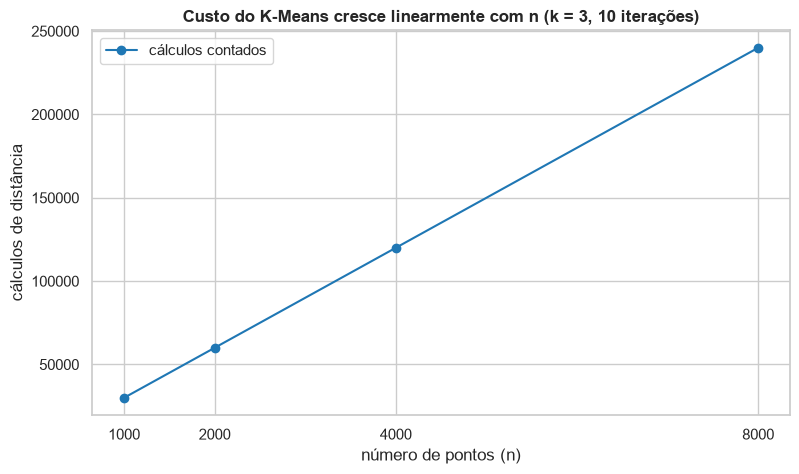

,cálculos de distância (10 iterações),iterações até convergir,cálculos até convergir,cálculos ÷ n
n,,,,
1000,30000,5,15000,30
2000,60000,7,42000,30
4000,120000,9,108000,30
8000,240000,6,144000,30


In [8]:
linhas_custo = []
for n in [1_000, 2_000, 4_000, 8_000]:
    X_n, _ = make_blobs(n_samples=n, centers=3, cluster_std=2.5, random_state=RANDOM_STATE)
    fixas = {"distâncias": 0}
    kmeans_do_zero(X_n, k=3, semente=RANDOM_STATE, max_iter=10, tol=0, contador=fixas)
    reais = {"distâncias": 0}
    _, _, _, iter_reais, _ = kmeans_do_zero(X_n, k=3, semente=RANDOM_STATE, contador=reais)
    linhas_custo.append({"n": n, "cálculos de distância (10 iterações)": fixas["distâncias"],
                         "iterações até convergir": iter_reais,
                         "cálculos até convergir": reais["distâncias"]})
custo = pd.DataFrame(linhas_custo).set_index("n")
custo["cálculos ÷ n"] = custo["cálculos de distância (10 iterações)"] // custo.index

fig, ax = plt.subplots()
ax.plot(custo.index, custo["cálculos de distância (10 iterações)"], marker="o", label="cálculos contados")
ax.set(title="Custo do K-Means cresce linearmente com n (k = 3, 10 iterações)",
       xlabel="número de pontos (n)", ylabel="cálculos de distância")
ax.set_xticks(custo.index)
ax.legend()
plt.show()
custo

Com o número de iterações fixo, os cálculos crescem **exatamente na proporção de n**: de 30.000 (n =
1.000) para 240.000 (n = 8.000). Dobrar n dobra o trabalho, e a coluna "cálculos ÷ n" fica constante
em k × i = 3 × 10 = 30. O gráfico é uma **reta**: crescimento linear, como o O(n·k·d·i) previa.

A coluna **iterações até convergir** mostra o outro fator da fórmula: o número de iterações varia de um
conjunto para outro e não depende só de n. Ele depende de como os pontos estão distribuídos e de
onde caíram os centroides iniciais. Por isso a análise de complexidade trata i como um parâmetro
separado. Na prática, o K-Means costuma convergir em poucas iterações, e na Seção IV, com 89.583
faixas, o modelo final convergiu em 17.

A coluna **cálculos até convergir** vem do mesmo contador, agora sem fixar as iterações: 15.000
para n = 1.000 (5 iterações) e 108.000 para n = 4.000 (9 iterações). O valor é sempre n × k × i,
e por isso não cresce em linha reta com n: n = 8.000 convergiu em 6 iterações e fez 144.000
cálculos, pouco mais que os 108.000 de n = 4.000.

### I.5 Como avaliar: inércia, Método do Cotovelo e silhueta

Como não há respostas certas, precisamos de medidas que digam se um agrupamento é bom.

**Inércia.** É a soma das distâncias ao quadrado de cada ponto até o centroide do seu grupo:

$$\text{inércia} = \sum_{j=1}^{k} \; \sum_{x \in \text{grupo } j} \lVert x - \mu_j \rVert^2$$

em que $\mu_j$ é o centroide do grupo $j$. Quanto **menor**, mais "apertados" estão os grupos. O
K-Means é, na verdade, um método para **minimizar a inércia**: cada atribuição e cada atualização
nunca a aumentam, e por isso ele sempre converge (embora possa parar num mínimo local, como vimos).

**Método do Cotovelo.** A inércia sempre diminui quando k aumenta: com k = n, cada ponto seria o
próprio centroide e a inércia seria zero. Então não adianta escolher o k de menor inércia. O método
treina o K-Means para vários k, desenha a inércia × k e procura o ponto em que a curva **para de cair
rápido**, o "cotovelo". Depois dele, mais grupos quase não melhoram o agrupamento. Veja no exemplo
de brinquedo:

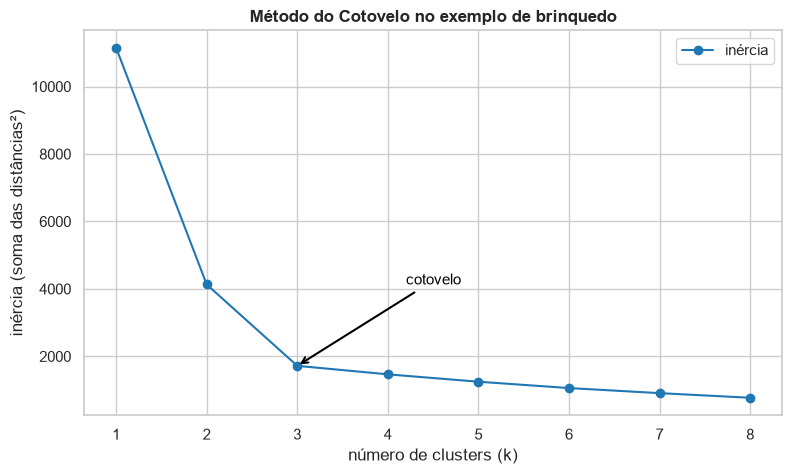

Inércia por k: {1: 11149, 2: 4131, 3: 1718, 4: 1466, 5: 1247, 6: 1059, 7: 909, 8: 771}


In [9]:
valores_k_brinquedo = range(1, 9)
inercias_brinquedo = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_brinquedo).inertia_
                      for k in valores_k_brinquedo]

fig, ax = plt.subplots()
ax.plot(list(valores_k_brinquedo), inercias_brinquedo, marker="o", label="inércia")
ax.annotate("cotovelo", xy=(3, inercias_brinquedo[2]), xytext=(4.2, inercias_brinquedo[1]),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.5), fontsize=11, color="black")
ax.set(title="Método do Cotovelo no exemplo de brinquedo",
       xlabel="número de clusters (k)", ylabel="inércia (soma das distâncias²)")
ax.set_xticks(list(valores_k_brinquedo))
ax.legend()
plt.show()
print("Inércia por k:", {k: round(v) for k, v in zip(valores_k_brinquedo, inercias_brinquedo)})

Aqui o cotovelo aparece em **k = 3**: a inércia despenca de k = 1 para 2 e de 2 para 3 e, a partir
daí, cai devagar. Como o exemplo foi gerado com 3 centros, é o resultado esperado. Com dados reais,
o cotovelo raramente é tão nítido (veremos isso na IV.1), e por isso usamos um critério
complementar.

**Silhueta.** Mede, para cada ponto, se ele está mais perto do seu grupo do que do grupo vizinho:

$$s = \frac{b - a}{\max(a, b)}$$

- $a$ = distância média do ponto até os outros pontos do **seu** grupo;
- $b$ = distância média do ponto até os pontos do grupo **vizinho mais próximo**.

O valor vai de −1 a 1: perto de **1**, o ponto está bem dentro do seu grupo; perto de **0**, está na
fronteira; **negativo**, estaria melhor no outro grupo. A silhueta do agrupamento é a média de todos
os pontos e, diferente da inércia, **não melhora sozinha** quando k aumenta: dá para comparar valores
de k diferentes. O preço é o custo O(n²), discutido na I.4.

## II. Ferramentas de Trabalho (Scikit-learn e Python)

### II.1 Bibliotecas e importações

Todas as bibliotecas da aula são importadas uma única vez, na célula **⚙️ Configuração do
ambiente**, no início do notebook (é ela que também imprime as versões). Todas já vêm instaladas no
Google Colab, então nada precisa ser instalado.

| Biblioteca | Para que serve | Onde aparece na aula |
|---|---|---|
| **numpy** (`np`) | cálculo com vetores e matrizes, de forma rápida | a implementação do zero (I.3), distâncias e médias |
| **pandas** (`pd`) | tabelas de dados (*DataFrames*): ler o CSV, filtrar, agrupar, cruzar | carga e limpeza (III.3), perfis e cruzamentos (V) |
| **matplotlib** (`plt`) | a base dos gráficos em Python | todos os gráficos de dispersão e de linha |
| **seaborn** (`sns`) | gráficos estatísticos prontos e um estilo visual uniforme | os mapas de calor (V) e a paleta de cores |
| **scikit-learn** (`sklearn`) | aprendizado de máquina: modelos, pré-processamento e métricas | ver os módulos abaixo |
| `sys` | informações do próprio Python | imprimir a versão do Python |
| `json` e `IPython.display` (`HTML`, `display`) | transformar dados do Python em texto que o JavaScript lê e mostrar uma página HTML na saída da célula | os dois simuladores (I.3 e V.2) |

Do scikit-learn, usamos cinco módulos:

| Import | Papel |
|---|---|
| `sklearn.cluster.KMeans` | o algoritmo K-Means (Seções I, II e IV) |
| `sklearn.preprocessing.StandardScaler` | a padronização das features (III.5) |
| `sklearn.metrics.silhouette_score` e `adjusted_rand_score` | a silhueta (IV.1) e o ARI, que compara agrupamentos (I.3 e IV.4) |
| `sklearn.decomposition.PCA` | a projeção em 2 dimensões do gráfico de centroides (IV.4) |
| `sklearn.datasets.make_blobs` | os pontos de brinquedo da Seção I |

### II.2 O KMeans do scikit-learn

O **scikit-learn** é a biblioteca de aprendizado de máquina mais usada em Python. Ela é gratuita, de
código aberto, e reúne dezenas de algoritmos (classificação, regressão, agrupamento…) com a **mesma
forma de uso**, o que facilita trocar um modelo por outro:

1. **Instanciar**: criar o modelo com os parâmetros escolhidos, ainda sem dados;
2. **Treinar**: `.fit(dados)` aprende com os dados;
3. **Usar**: `.predict(novos_dados)` aplica o que foi aprendido a dados novos. Tudo o que o
   modelo aprendeu fica em **atributos terminados em `_`** (como `labels_`).

O K-Means fica em `sklearn.cluster.KMeans`. Os parâmetros principais:

| Parâmetro | O que controla | Padrão | Nesta aula |
|---|---|---|---|
| `n_clusters` | o número de grupos k | 8 | 3 (brinquedo) e `K_ESCOLHIDO` = 7 (músicas) |
| `init` | como escolher os centroides iniciais: `'k-means++'`, `'random'` ou uma matriz pronta | `'k-means++'` | o padrão; uma matriz na I.3, para comparar |
| `n_init` | quantas inicializações diferentes testar (fica com a de menor inércia) | `'auto'` | 10 |
| `max_iter` | número máximo de iterações por inicialização | 300 | o padrão |
| `tol` | tolerância do critério de parada (quanto os centroides ainda podem se mexer, em relação à variância dos dados; na `kmeans_do_zero` é um deslocamento absoluto) | 0,0001 | o padrão |
| `random_state` | semente do sorteio, para resultados reprodutíveis | `None` | `RANDOM_STATE` = 42 |

E os atributos que o modelo preenche depois do `.fit`:

| Atributo | O que contém |
|---|---|
| `labels_` | o grupo de cada ponto (o mesmo que os rótulos da nossa função) |
| `cluster_centers_` | os centroides (k × d) |
| `inertia_` | a inércia do agrupamento final |
| `n_iter_` | quantas iterações a melhor inicialização levou |

Vamos ver tudo isso no exemplo de brinquedo:

In [10]:
modelo_demo = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)  # 1. instanciar
modelo_demo.fit(X_brinquedo)                                                # 2. treinar

print("labels_ (10 primeiros):", modelo_demo.labels_[:10])
print("cluster_centers_:\n", np.round(modelo_demo.cluster_centers_, 2))
print(f"inertia_: {modelo_demo.inertia_:.1f}")
print(f"n_iter_: {modelo_demo.n_iter_}")

pontos_novos = np.array([[-8.0, 8.0], [0.0, 4.0]])                         # 3. usar
print("predict de dois pontos novos:", modelo_demo.predict(pontos_novos))

labels_ (10 primeiros): [0 0 1 2 1 2 0 0 1 2]
cluster_centers_:
 [[-3.04  8.62]
 [-6.59 -7.1 ]
 [ 4.5   2.4 ]]
inertia_: 1718.2
n_iter_: 3
predict de dois pontos novos: [0 2]


O modelo chegou à mesma inércia da implementação do zero com a semente 42 (I.3). O `predict`
responde a que grupo cada ponto **novo** pertence, usando o centroide mais próximo. No caso das
músicas, isso permitiria classificar uma faixa lançada amanhã sem treinar tudo de novo.

**k-means++ × inicialização aleatória.** No Experimente da I.3, a semente 0 caiu num mínimo local
porque dois centroides iniciais foram sorteados no mesmo grupo. A inicialização **k-means++**, padrão
do scikit-learn, evita isso: sorteia o primeiro centroide e escolhe os seguintes com mais chance de
ficarem **longe** dos já escolhidos. A célula abaixo compara as duas estratégias com **uma única
inicialização** (`n_init=1`) em 20 sementes diferentes, contando quantas caem num mínimo local
(inércia mais de 1% acima da melhor).

In [11]:
melhor_inercia = modelo_demo.inertia_
comparacao_init = []
for estrategia in ["random", "k-means++"]:
    inercias_init = [KMeans(n_clusters=3, init=estrategia, n_init=1, random_state=s).fit(X_brinquedo).inertia_
                     for s in range(20)]
    comparacao_init.append({
        "inicialização": estrategia,
        "mínimos locais (em 20 sementes)": sum(i > 1.01 * melhor_inercia for i in inercias_init),
        "pior inércia": round(max(inercias_init), 1),
    })
pd.DataFrame(comparacao_init).set_index("inicialização")

,mínimos locais (em 20 sementes),pior inércia
inicialização,,
random,4,3880.6
k-means++,1,3878.8


A inicialização puramente aleatória caiu num mínimo local em **4 das 20** sementes (a pior com
inércia 3.880,6, mais que o dobro da melhor, 1.718,2), e a k-means++ em só **1**. Por isso, nesta aula, todos os modelos com os dados de músicas usam o padrão `init='k-means++'` **e**
`n_init=10`: mesmo que uma inicialização dê azar, as outras nove compensam, e o scikit-learn fica com
a de menor inércia.

## III. Escolha do Tema e Preparação dos Dados

### III.1 Tema: por que agrupar músicas?

O Spotify tem dezenas de milhões de faixas. Ninguém consegue ouvir todas e anotar à mão se cada
uma é "calma", "dançante" ou "pesada". Mesmo assim, é exatamente esse tipo de informação que o
app usa o tempo todo:

- **Playlists automáticas**: "Para focar", "Treino", "Relaxar". Cada uma junta músicas que soam
  parecidas, mesmo sendo de artistas e gêneros diferentes.
- **Recomendação**: se você gosta de uma faixa, as faixas que estão no mesmo grupo dela são boas
  candidatas para tocar em seguida.
- **Descoberta de "climas"**: um samba e um pop podem ter a mesma energia dançante, e uma faixa
  de música clássica pode estar mais perto de um lo-fi do que de outra clássica. Os gêneros
  não contam essa história inteira.

Para cada faixa, o Spotify calculou números que descrevem o som: o quanto ela é dançante,
enérgica, acústica, alegre, falada etc. Não existe uma resposta certa dizendo a que grupo cada
música pertence. É um problema de **aprendizado não supervisionado** (Seção I): damos ao K-Means
só as características e deixamos que ele descubra os grupos.

> **A pergunta desta aula:** que perfis de som existem nas músicas do Spotify, e onde a música
> brasileira se encaixa neles?

O caminho até o modelo, nesta seção:

1. **III.2** conhecer o dataset e o que significa cada coluna;
2. **III.3** carregar e limpar os dados;
3. **III.4** escolher quais colunas entram no agrupamento;
4. **III.5** colocar todas as colunas na mesma escala.

### III.2 O dataset: origem e dicionário de variáveis

**Origem.** Usamos o [*Spotify Tracks Dataset*](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset), publicado no Hugging Face por
**Maharshi Pandya** sob a licença **BSD**. Os dados foram coletados com a API do Spotify e
trazem **114.000 linhas**: 1.000 faixas para cada um dos **114 gêneros**.

> ⚠️ Em novembro de 2024, o Spotify deixou de oferecer as *audio features* (dançabilidade,
> energia etc.) na sua API para novos aplicativos. Hoje não dá para coletar esses números de
> novo, e por isso trabalhamos com este retrato estático, lido direto do Hugging Face.

**Dicionário de variáveis.** Cada linha é uma combinação (faixa, gênero). As faixas de valores
abaixo são as dos dados brutos, antes da limpeza da III.3.

| Coluna | Significado | Valores | Entra no agrupamento? |
|---|---|---|---|
| `track_id` | identificador da faixa no Spotify | texto | não: é a chave |
| `artists` | artista(s), separados por `;` | texto | não: usado nos exemplos da V |
| `album_name` | nome do álbum | texto | não |
| `track_name` | nome da faixa | texto | não: usado nos exemplos da V |
| `popularity` | popularidade calculada pelo Spotify (quantidade e recência de execuções) | 0 a 100 | não: contexto, não é som |
| `duration_ms` | duração em milissegundos | 0 a ≈ 5,2 milhões (≈ 87 min) | não: contexto, não é som |
| `explicit` | a letra tem conteúdo explícito? | `True`/`False` | não: contexto, não é som |
| `danceability` | o quanto a faixa é boa para dançar (ritmo estável, batida forte) | 0 a 0,985 | **sim** |
| `energy` | intensidade percebida: rápida, alta, barulhenta | 0 a 1 | **sim** |
| `key` | tom da música (0 = Dó, 1 = Dó♯, …, 11 = Si) | 0 a 11 | não: categórica |
| `loudness` | volume médio, em decibéis (dB) | −49,5 a +4,5 | **sim** |
| `mode` | modo: 1 = maior, 0 = menor | 0 ou 1 | não: categórica |
| `speechiness` | presença de fala (perto de 1 = podcast, *stand-up*) | 0 a 0,965 | **sim** |
| `acousticness` | confiança de que a faixa é acústica | 0 a 0,996 | **sim** |
| `instrumentalness` | probabilidade de a faixa não ter voz | 0 a 1 | **sim** |
| `liveness` | probabilidade de ter sido gravada ao vivo, com plateia | 0 a 1 | **sim** |
| `valence` | positividade: alto = alegre, eufórica; baixo = triste, tensa | 0 a 0,995 | **sim** |
| `tempo` | andamento, em batidas por minuto (BPM) | 0 a 243 | **sim** (os zeros são inválidos, III.3) |
| `time_signature` | compasso estimado (3 = 3/4, 4 = 4/4…) | 0 a 5 | não: categórica |
| `track_genre` | gênero atribuído pela fonte | 114 gêneros | não: reservada para validar os grupos na V.3 |

A III.4 explica, uma por uma, por que essas 9 colunas entram e as outras ficam de fora.

### III.3 Carregamento e limpeza

**Carregando os dados.** O arquivo CSV (≈ 20 MB) é lido direto do endereço guardado em
`URL_DATASET`, sem upload e sem login, então o projeto roda igual em qualquer Colab.

Três detalhes do código:

- `index_col=0`: a primeira coluna do arquivo é só um número de linha, sem nome. Ela vira o
  índice da tabela e não uma coluna de dados.
- **Fonte de reserva**: se o Hugging Face não responder, o código tenta uma cópia idêntica do
  arquivo guardada no repositório do projeto, no GitHub (`URL_DATASET_RESERVA`). A saída diz de
  qual fonte os dados vieram.
- `try`/`except`: cada tentativa fica protegida. Se as duas fontes falharem, aparece uma mensagem
  em português com o link da página do dataset, em vez de só um erro técnico.

In [12]:
fontes = [("Hugging Face", URL_DATASET), ("cópia de reserva no GitHub", URL_DATASET_RESERVA)]

df_bruto = None
for nome_fonte, url in fontes:
    try:
        df_bruto = pd.read_csv(url, index_col=0)
        print(f"Dados carregados de: {nome_fonte}")
        break
    except Exception as erro:
        print(f"Não foi possível baixar de {nome_fonte}: {erro}")

if df_bruto is None:
    raise RuntimeError(
        "Nenhuma fonte do dataset respondeu. Confira a conexão com a internet ou baixe pela "
        "página original: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset"
    )

linhas, colunas = df_bruto.shape
print(f"df_bruto: {linhas:,} linhas × {colunas} colunas".replace(",", "."))
df_bruto.head()

Dados carregados de: Hugging Face
df_bruto: 114.000 linhas × 20 colunas


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


A primeira linha da saída diz de qual fonte os dados vieram. Vieram **114.000 linhas e 20
colunas**, como a página do dataset descreve. As primeiras linhas
mostram as três partes da tabela: a identificação da faixa (`track_id`, artista, álbum, nome),
os números que descrevem o som (`danceability` até `tempo`) e, na última coluna, o gênero.

Agora vamos ver o **tipo** de cada coluna e se alguma tem valores faltando.

In [13]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

Os tipos batem com o dicionário da III.2: as 9 *features* de áudio são números decimais
(`float64`), `key`, `mode` e `time_signature` são inteiros e `explicit` é verdadeiro/falso.

Repare na coluna **Non-Null Count**: `artists`, `album_name` e `track_name` têm **113.999**
valores, um a menos que as outras. Existe uma linha com dados faltando, e é por ela que a limpeza
começa.

**Limpando os dados.** Três regras, aplicadas nesta ordem:

1. **Linhas com valor ausente** são removidas. É a linha sem artista, álbum e nome que a
   `info()` mostrou. Sem nome, não daria para usá-la nos exemplos da Seção V.
2. **Linhas idênticas** (todas as 20 colunas iguais) são cópias acidentais e são removidas.
3. **`tempo` = 0** é removido. Nenhuma música tem 0 batidas por minuto: esse valor aparece em
   faixas de silêncio, ruído ou só fala, em que o Spotify não conseguiu medir o andamento. É um
   valor **inválido**, não um valor pequeno, e atrapalharia as distâncias.

O resultado se chama `df_pares`, porque cada linha ainda é um par (faixa, gênero).

In [14]:
sem_ausentes = df_bruto.dropna()
sem_identicas = sem_ausentes.drop_duplicates()
df_pares = sem_identicas[sem_identicas["tempo"] > 0].reset_index(drop=True)

limpeza = pd.DataFrame({
    "regra": ["1. valor ausente", "2. linha idêntica", "3. tempo = 0"],
    "linhas removidas": [
        len(df_bruto) - len(sem_ausentes),
        len(sem_ausentes) - len(sem_identicas),
        len(sem_identicas) - len(df_pares),
    ],
})
n_pares = f"{len(df_pares):,}".replace(",", ".")
print(f"df_pares: {n_pares} pares (faixa, gênero)")
limpeza

df_pares: 113.392 pares (faixa, gênero)


,regra,linhas removidas
0,1. valor ausente,1
1,2. linha idêntica,450
2,3. tempo = 0,157


A limpeza removeu **1 linha** com ausentes, **450 linhas idênticas** e **157 faixas com
`tempo` = 0**. Sobraram **113.392 pares**. Perdemos menos de 0,6% dos dados.

**Uma faixa, vários gêneros.** O dataset tem 1.000 linhas por gênero, e a mesma faixa pode
aparecer em mais de um: uma música pode estar em `mpb` e também em `brazil`. Quantos gêneros
cada faixa tem?

In [15]:
generos_por_faixa = df_pares.groupby("track_id")["track_genre"].nunique()
(generos_por_faixa.value_counts().sort_index()
    .rename_axis("gêneros da faixa").to_frame("faixas"))

,faixas
gêneros da faixa,
1,73284
2,11424
3,2955
4,1361
5,431
6,104
7,21
8,2
9,1


A maioria das faixas (73.284) aparece em um gênero só, mas **16.299 faixas aparecem em dois ou
mais**, e uma delas chega a 9 gêneros. Juntas, essas repetições somam 23.809 linhas a mais.

**Por que isso importa para o K-Means?** O centroide de um grupo é a **média** dos pontos do
grupo. Se treinarmos com `df_pares`, uma faixa que está em 9 gêneros entra 9 vezes nessa média e
puxa o centroide para perto dela, só porque a fonte a classificou em mais gêneros. Nenhuma faixa
deveria pesar mais que outra.

Por isso a base de treino terá **uma linha por faixa**. Antes, conferimos com um `assert` (uma
checagem que interrompe o notebook se falhar) que as cópias de uma faixa têm exatamente os
mesmos valores de áudio, para garantir que não perdemos informação ao ficar com uma delas.

Repare que **não escolhemos nem descartamos nenhum gênero**: o treino nem olha para o gênero, e na
Seção V o grupo de cada faixa volta para todos os gêneros em que ela aparece.

In [16]:
faixas_divergentes = (df_pares.groupby("track_id")[FEATURES].nunique() > 1).any(axis=1).sum()
assert faixas_divergentes == 0, f"{faixas_divergentes} faixas têm áudio diferente entre as cópias"

df_faixas = (df_pares.drop_duplicates("track_id")
             .drop(columns="track_genre")
             .reset_index(drop=True))
print(f"Faixas com áudio diferente entre as cópias: {faixas_divergentes}")
n_faixas = f"{len(df_faixas):,}".replace(",", ".")
n_pares = f"{len(df_pares):,}".replace(",", ".")
print(f"df_faixas: {n_faixas} faixas únicas (base de treino)")
print(f"df_pares:  {n_pares} pares, com {df_pares['track_genre'].nunique()} gêneros "
      "(guardado para a análise por gênero da V.3)")

Faixas com áudio diferente entre as cópias: 0
df_faixas: 89.583 faixas únicas (base de treino)
df_pares:  113.392 pares, com 114 gêneros (guardado para a análise por gênero da V.3)


O `assert` passou: **nenhuma** faixa tem valores de áudio diferentes entre as cópias. A base de
treino `df_faixas` tem **89.583 faixas únicas**.

Duas decisões ficam registradas aqui:

- `df_faixas` **não tem a coluna `track_genre`**. Ela foi retirada de propósito: como cada faixa
  pode ter vários gêneros, guardar só um seria arbitrário, e o gênero não deve chegar perto do
  treino (III.4).
- `df_pares` continua guardado, com os 114 gêneros. Na Seção V, cada faixa recebe o seu cluster,
  e esse rótulo volta para **todas** as linhas dela em `df_pares`. Assim nenhum gênero perde
  faixas na análise.

### III.4 Escolha das features

Uma *feature* (característica) é uma coluna que o K-Means usa para medir se duas músicas são
parecidas. A pergunta desta aula é sobre **som**, então entram só as colunas que descrevem o som,
e todas elas precisam ser números contínuos, para que a distância entre duas faixas faça sentido.

| Grupo | Colunas | Decisão e motivo |
|---|---|---|
| Som, contínuas | `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` | **entram** (são as 9 `FEATURES`) |
| Som, categóricas | `key`, `mode`, `time_signature` | **ficam fora**: são códigos, não quantidades. O tom 11 (Si) não é "o dobro" do tom 5 (Fá), e a distância entre os números não significa nada musicalmente |
| Contexto | `popularity`, `duration_ms`, `explicit` | **ficam fora**: dizem como a faixa foi recebida ou embalada, não como ela soa. Elas voltam na Seção V para ajudar a interpretar os grupos |
| Identificação | `track_id`, `artists`, `album_name`, `track_name` | **ficam fora**: são nomes, não medidas. Servem para os exemplos da Seção V |
| Rótulo da fonte | `track_genre` | **fica fora, de propósito**: é a "resposta" que vamos usar na V.3 para conferir se os grupos fazem sentido. Se ela entrasse no treino, o K-Means apenas copiaria os gêneros e a conferência viraria um círculo vicioso (o chamado **vazamento de rótulo**) |

Vamos olhar o resumo estatístico das 9 features escolhidas:

In [17]:
df_faixas[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
danceability,89583.0,0.563,0.175,0.051,0.450,0.576,0.692,0.985
energy,89583.0,0.635,0.256,0.000,0.458,0.677,0.853,1.000
loudness,89583.0,-8.475,5.179,-46.591,-10.308,-7.177,-5.104,4.532
speechiness,89583.0,0.088,0.113,0.022,0.036,0.049,0.086,0.965
acousticness,89583.0,0.328,0.338,0.000,0.017,0.188,0.624,0.996
instrumentalness,89583.0,0.173,0.323,0.000,0.000,0.000,0.094,1.000
liveness,89583.0,0.217,0.194,0.009,0.098,0.132,0.278,1.000
valence,89583.0,0.470,0.262,0.000,0.250,0.458,0.683,0.995
tempo,89583.0,122.272,29.707,30.200,99.515,122.021,140.087,243.372


A tabela confirma que não há valores faltando (`count` = 89.583 em todas) e revela o problema que
a III.5 resolve: **as escalas são muito diferentes**.

- Sete features vão de **0 a 1** (`danceability`, `energy`, `speechiness`, `acousticness`,
  `instrumentalness`, `liveness`, `valence`), com desvio-padrão (`std`) entre 0,11 e 0,34.
- `loudness` vai de **−46,6 a +4,5 dB**, com desvio de 5,2.
- `tempo` vai de **30 a 243 BPM**, com desvio de 29,7, cerca de **170 vezes** o desvio de
  `danceability` (0,175).

Se usarmos esses números como estão, uma diferença de 30 BPM vai "valer" muito mais do que a
diferença entre uma música nada dançante (0) e uma totalmente dançante (1).

### III.5 Padronização com StandardScaler

**Por que o K-Means precisa disso?** O K-Means decide se duas músicas são parecidas pela
**distância euclidiana**: a "distância em linha reta" entre dois pontos, a mesma da régua e do
teorema de Pitágoras. A figura abaixo mostra a ideia com as duas primeiras faixas da base,
olhando só duas features (dançabilidade e energia).

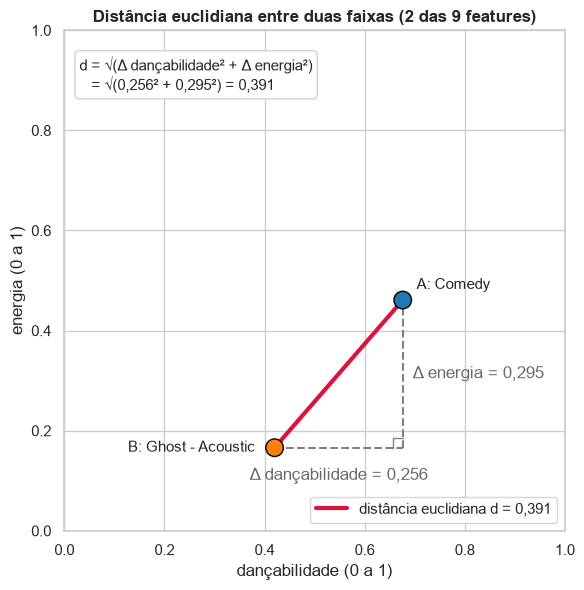

In [18]:
# @title Figura: distância euclidiana entre duas faixas (clique duas vezes para ver o código)
faixa_a = df_faixas.iloc[0]
faixa_b = df_faixas.iloc[1]
xa, ya = faixa_a["danceability"], faixa_a["energy"]
xb, yb = faixa_b["danceability"], faixa_b["energy"]
dx, dy = xa - xb, ya - yb
d = np.hypot(dx, dy)  # raiz quadrada de dx² + dy²

def br(valor):  # vírgula decimal nos rótulos
    return f"{valor:.3f}".replace(".", ",")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.plot([xb, xa], [yb, yb], "--", color="gray", lw=1.5)  # cateto horizontal
ax.plot([xa, xa], [yb, ya], "--", color="gray", lw=1.5)  # cateto vertical
ax.plot([xb, xa], [yb, ya], color="crimson", lw=3, label=f"distância euclidiana d = {br(d)}")
lado = 0.02  # marca do ângulo reto
ax.plot([xa - lado, xa - lado, xa], [yb, yb + lado, yb + lado], color="gray", lw=1)
ax.scatter([xa, xb], [ya, yb], s=160, color=["tab:blue", "tab:orange"], edgecolor="black", zorder=3)

ax.annotate(f"A: {faixa_a['track_name']}", (xa, ya), xytext=(10, 8), textcoords="offset points", fontsize=11)
ax.annotate(f"B: {faixa_b['track_name']}", (xb, yb), xytext=(-14, 0), textcoords="offset points",
            fontsize=11, ha="right", va="center")
ax.text((xa + xb) / 2, yb - 0.04, f"Δ dançabilidade = {br(dx)}", ha="center", va="top", color="dimgray")
ax.text(xa + 0.02, (ya + yb) / 2, f"Δ energia = {br(dy)}", ha="left", va="center", color="dimgray")
ax.text(0.03, 0.95, f"d = √(Δ dançabilidade² + Δ energia²)\n   = √({br(dx)}² + {br(dy)}²) = {br(d)}",
        transform=ax.transAxes, va="top", fontsize=11,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="lightgray"))

ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal",
       title="Distância euclidiana entre duas faixas (2 das 9 features)",
       xlabel="dançabilidade (0 a 1)", ylabel="energia (0 a 1)")
ax.legend(loc="lower right")
plt.show()

A distância entre as duas faixas é a **hipotenusa** (linha vermelha) de um triângulo retângulo
cujos catetos são as diferenças em cada feature: **0,256** em dançabilidade e **0,295** em energia.
Pelo teorema de Pitágoras, d = √(0,256² + 0,295²) ≈ **0,391**.

Com as 9 features, a conta é a mesma, só que com 9 diferenças em vez de 2:

$$d(A, B) = \sqrt{(\Delta_1)^2 + (\Delta_2)^2 + \dots + (\Delta_9)^2}$$

Na figura, as duas features vão de 0 a 1, então pesam de forma parecida. O problema aparece
quando uma delas é medida em outra escala. Uma diferença de 30 BPM em `tempo` entra na soma como
30² = 900, enquanto a maior diferença possível em dançabilidade (de 0 a 1) entra como 1² = 1. Uma
feature com números grandes produz diferenças grandes e **domina a soma**: o agrupamento passaria
a ser praticamente sobre `tempo` e `loudness`, ignorando as outras sete.

A **padronização** resolve isso transformando cada feature com a fórmula

$$z = \frac{x - \text{média}}{\text{desvio-padrão}}$$

Depois dela, toda feature tem **média 0 e desvio-padrão 1**. Cada valor passa a dizer "quantos
desvios acima ou abaixo da média" a faixa está, e uma diferença de 1 tem o mesmo peso em
qualquer feature.

No código, o `StandardScaler` do scikit-learn **aprende** a média e o desvio de cada feature com
`fit` e **aplica** a fórmula com `transform` (`fit_transform` faz os dois). O `scaler` fica
guardado: na Seção V ele faz a conta inversa (`inverse_transform`), para descrever os grupos de
volta em BPM, dB e assim por diante.

In [19]:
scaler = StandardScaler()
X = scaler.fit_transform(df_faixas[FEATURES])

escalas = pd.DataFrame({
    "média antes": df_faixas[FEATURES].mean(),
    "desvio antes": df_faixas[FEATURES].std(ddof=0),
    "média depois": X.mean(axis=0),
    "desvio depois": X.std(axis=0),
}, index=FEATURES)
print(f"X: {X.shape[0]:,} faixas × {X.shape[1]} features".replace(",", "."))
escalas.round(3) + 0.0  # o "+ 0.0" só troca o -0.0 por 0.0 na exibição

X: 89.583 faixas × 9 features


,média antes,desvio antes,média depois,desvio depois
danceability,0.563,0.175,0.0,1.0
energy,0.635,0.256,0.0,1.0
loudness,-8.475,5.179,0.0,1.0
speechiness,0.088,0.113,0.0,1.0
acousticness,0.328,0.338,0.0,1.0
instrumentalness,0.173,0.323,0.0,1.0
liveness,0.217,0.194,0.0,1.0
valence,0.470,0.262,0.0,1.0
tempo,122.272,29.707,0.0,1.0


Antes, as médias iam de 0,09 (`speechiness`) a 122 (`tempo`), e os desvios de 0,11 a 29,7.
Depois da padronização, **todas as 9 colunas de `X` têm média 0 e desvio 1**. `X` é a matriz que
o K-Means vai receber na Seção IV: 89.583 linhas (faixas) e 9 colunas (features).

**Um exemplo concreto.** Vamos comparar as duas primeiras faixas da base e ver quanto cada
feature contribui para a distância entre elas, sem e com padronização.

In [20]:
faixa_a, faixa_b = df_faixas.iloc[0], df_faixas.iloc[1]
print(f"A: {faixa_a['track_name']} ({faixa_a['artists']})")
print(f"B: {faixa_b['track_name']} ({faixa_b['artists']})")

dif2_bruta = (faixa_a[FEATURES].astype(float) - faixa_b[FEATURES].astype(float)) ** 2
dif2_padronizada = pd.Series((X[0] - X[1]) ** 2, index=FEATURES)

contribuicao = pd.DataFrame({
    "sem padronizar (%)": 100 * dif2_bruta / dif2_bruta.sum(),
    "padronizado (%)": 100 * dif2_padronizada / dif2_padronizada.sum(),
}).round(1)
print(f"Distância sem padronizar: {np.sqrt(dif2_bruta.sum()):.2f}")
print(f"Distância padronizada:    {np.sqrt(dif2_padronizada.sum()):.2f}")
contribuicao

A: Comedy (Gen Hoshino)
B: Ghost - Acoustic (Ben Woodward)
Distância sem padronizar: 14.83
Distância padronizada:    4.43


,sem padronizar (%),padronizado (%)
danceability,0.0,10.9
energy,0.0,6.8
loudness,50.0,20.9
speechiness,0.0,1.8
acousticness,0.4,35.4
instrumentalness,0.0,0.0
liveness,0.0,8.9
valence,0.1,14.8
tempo,49.4,0.6


Sem padronizar, **`loudness` (50,0%) e `tempo` (49,4%) respondem por 99,4% da distância** entre
as duas faixas, e `danceability`, que é bem diferente entre elas (0,68 contra 0,42), contribui
com **0,0%**. Para o K-Means, essas faixas seriam diferentes só porque uma é mais alta e mais
rápida que a outra.

Depois de padronizar, a distância passa a refletir o som como um todo: a maior contribuição vem
de `acousticness` (35,4%), já que "Ghost - Acoustic" é acústica e a outra não. `tempo`, cuja
diferença de 10 BPM é pequena para os padrões do dataset, cai para 0,6%. É por isso que o
K-Means sempre vem depois da padronização.

> **Resumo da Seção III:** `df_faixas` (89.583 faixas únicas), `df_pares` (113.392 pares faixa ×
> gênero, para a Seção V), `FEATURES` (9 colunas de som), `scaler` (para voltar à escala
> original) e `X` (a matriz padronizada que entra no K-Means).

## IV. Implementação e Aplicação Prática

### IV.1 Definindo k: Método do Cotovelo (e silhueta)

O K-Means precisa que a gente diga **quantos grupos (k)** procurar. Não existe um k "certo"
escrito nos dados, então vamos decidir com três critérios, nesta ordem:

1. **Método do Cotovelo**: onde a inércia para de cair rápido;
2. **Silhueta**: entre os candidatos do cotovelo, qual separa melhor os grupos;
3. **Interpretabilidade**: se cada grupo tem um perfil musical que dá para descrever.

**Inércia** é a soma das distâncias ao quadrado de cada faixa até o centroide do seu grupo:
quanto menor, mais "apertados" estão os grupos. Ela **sempre** diminui quando k aumenta (com mais
centroides, cada ponto fica mais perto de algum), então não adianta procurar o k com a menor
inércia. O que interessa é **onde a queda desacelera**: a partir dali, criar mais grupos quase não
melhora nada. No gráfico, esse ponto parece o cotovelo de um braço dobrado.

O código treina um K-Means para cada k de 1 a 10 com os dados padronizados `X`. Os modelos ficam
guardados em `modelos_por_k` para serem reaproveitados pela silhueta e pela análise dos perfis,
sem treinar tudo de novo. `n_init=10` roda o K-Means com 10 inicializações diferentes e fica com a
melhor, para não depender da sorte do sorteio inicial.

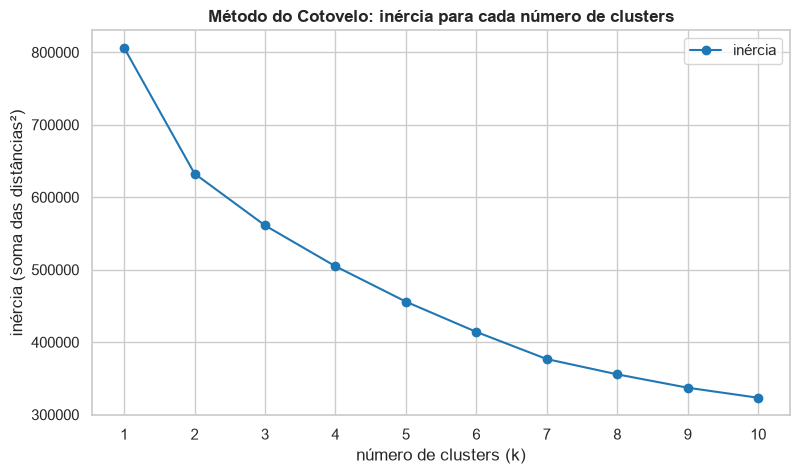

,inércia,queda em relação ao k anterior (%)
k,,
1,806247,NaN
2,632596,21.5
3,561059,11.3
4,504715,10.0
5,455853,9.7
6,414123,9.2
7,376640,9.1
8,355565,5.6
9,337118,5.2


In [21]:
valores_k = range(1, 11)
modelos_por_k = {
    k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X) for k in valores_k
}
inercias = [modelos_por_k[k].inertia_ for k in valores_k]

cotovelo = pd.DataFrame({"inércia": inercias}, index=pd.Index(valores_k, name="k"))
cotovelo["queda em relação ao k anterior (%)"] = (-100 * cotovelo["inércia"].pct_change()).round(1)

fig, ax = plt.subplots()
ax.plot(list(valores_k), inercias, marker="o", label="inércia")
ax.set(title="Método do Cotovelo: inércia para cada número de clusters",
       xlabel="número de clusters (k)", ylabel="inércia (soma das distâncias²)")
ax.set_xticks(list(valores_k))
ax.legend()
plt.show()
cotovelo.assign(inércia=cotovelo["inércia"].round().astype(int))

A curva é **suave, sem um cotovelo nítido**, e isso é comum em dados reais. A tabela ajuda a ver
onde a queda desacelera:

- de k = 1 para k = 2 a inércia cai **21,5%**: é a primeira dobra;
- de k = 2 até k = 7, cada grupo a mais ainda remove **cerca de 9 a 11%** da inércia (11,3%, 10,0%, 9,7%,
  9,2%, 9,1%);
- depois de k = 7, a queda cai para **5,6%**, 5,2% e 4,1%: é a segunda dobra, mais suave.

O cotovelo sozinho não decide. Ele indica que vale a pena ir além de k = 2 e que, depois de k = 7,
cada grupo a mais rende pouco. Os candidatos ficam entre **k = 5 e k = 7**. A silhueta ajuda a
escolher entre eles.

**Silhueta.** Para cada faixa, a silhueta compara duas distâncias: a média até as faixas do
**próprio** grupo e a média até as faixas do grupo **vizinho mais próximo**. O resultado vai de
−1 a 1:

- perto de **1**: a faixa está bem no meio do seu grupo, longe dos outros;
- perto de **0**: a faixa está na fronteira entre dois grupos;
- **negativo**: a faixa parece estar no grupo errado.

A nota do agrupamento é a média das silhuetas de todas as faixas. Diferente da inércia, ela **não**
melhora sozinha quando k aumenta, então dá para comparar valores de k diferentes. A silhueta só
existe a partir de k = 2.

**Por que usar uma amostra?** A silhueta exata compara cada faixa com todas as outras: são
n² distâncias, ou seja, complexidade **O(n²)**. Com 89.583 faixas, seriam cerca de 8 bilhões de
distâncias, o que levaria minutos e muitos GB de memória. Com uma amostra de
`TAMANHO_AMOSTRA_SILHUETA = 10.000` faixas (≈ 100 milhões de distâncias), o cálculo
fica rápido. Como a amostra é sorteada com `RANDOM_STATE`, é sempre a mesma, e todos os k são
avaliados com as mesmas faixas.

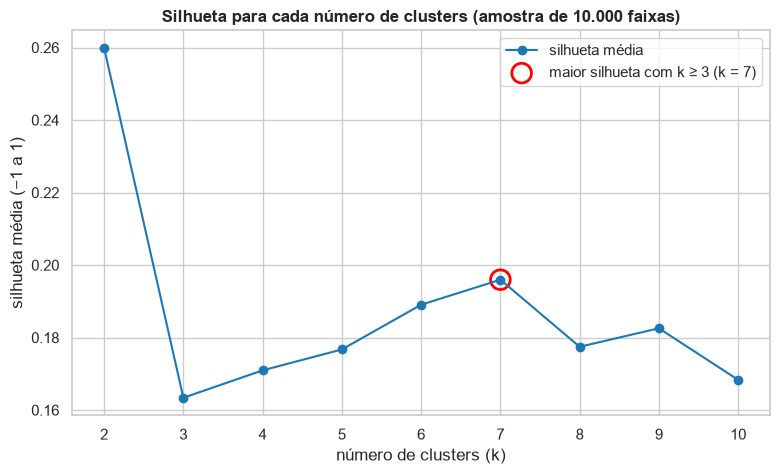

,silhueta
k,
2,0.260
3,0.163
4,0.171
5,0.177
6,0.189
7,0.196
8,0.177
9,0.183
10,0.168


In [22]:
silhuetas = [
    silhouette_score(X, modelos_por_k[k].labels_,
                     sample_size=TAMANHO_AMOSTRA_SILHUETA, random_state=RANDOM_STATE)
    for k in range(2, 11)
]
tabela_silhueta = pd.DataFrame({"silhueta": silhuetas}, index=pd.Index(range(2, 11), name="k"))
melhor_k = tabela_silhueta.loc[3:, "silhueta"].idxmax()

fig, ax = plt.subplots()
ax.plot(tabela_silhueta.index, tabela_silhueta["silhueta"], marker="o", label="silhueta média")
ax.scatter([melhor_k], [tabela_silhueta.loc[melhor_k, "silhueta"]], s=200, facecolors="none",
           edgecolors="red", linewidths=2, label=f"maior silhueta com k ≥ 3 (k = {melhor_k})")
ax.set(title=f"Silhueta para cada número de clusters (amostra de {TAMANHO_AMOSTRA_SILHUETA:,} faixas)".replace(",", "."),
       xlabel="número de clusters (k)", ylabel="silhueta média (−1 a 1)")
ax.set_xticks(range(2, 11))
ax.legend()
plt.show()
tabela_silhueta.round(3)

- **k = 2** tem a maior silhueta (**0,260**), mas dois grupos são genéricos demais para responder
  à pergunta da aula ("que perfis de som existem?"). Por isso a comparação fica entre os
  candidatos que o cotovelo indicou.
- Entre os candidatos, a silhueta cresce de **0,177 (k = 5)** para **0,189 (k = 6)** e chega ao
  máximo em **0,196 (k = 7)**, a maior de todas para k ≥ 3. Depois de k = 7 ela volta a cair
  (0,177 em k = 8).
- Para k ≥ 3, todos os valores são **baixos** (abaixo de 0,2). Isso quer dizer que os grupos de músicas se
  **sobrepõem**: muitas faixas ficam na fronteira entre dois perfis. Faz sentido, porque não existe
  uma linha nítida entre "dançante" e "intenso". Voltamos a isso nas limitações (V.4).

Cotovelo e silhueta apontam para o mesmo lugar: **k = 7**. Falta o terceiro critério.

**Interpretabilidade.** Um k só é útil se cada grupo puder ser descrito em palavras. Para comparar
os candidatos, a tabela abaixo mostra, para cada grupo de k = 5, 6 e 7, o tamanho e as **duas
features mais marcantes** do seu centroide. Os valores estão em **desvios-padrão em relação à
média**, por causa da padronização: +1,9 em `instrumentalness` quer dizer "quase dois desvios acima
da média das faixas".

In [23]:
candidatos = [5, 6, 7]
resumo_candidatos = pd.DataFrame({
    "inércia": [inercias[k - 1] for k in candidatos],
    "silhueta": [silhuetas[k - 2] for k in candidatos],
}, index=pd.Index(candidatos, name="k")).round({"inércia": 0, "silhueta": 3})
display(resumo_candidatos)

linhas = []
for k in candidatos:
    centros = pd.DataFrame(modelos_por_k[k].cluster_centers_, columns=FEATURES)
    tamanhos_k = np.bincount(modelos_por_k[k].labels_)
    for c in range(k):
        marcantes = centros.loc[c].abs().nlargest(2).index
        linhas.append({
            "k": k, "cluster": c, "faixas": tamanhos_k[c],
            "features mais marcantes (desvios da média)":
                ", ".join(f"{f} {centros.loc[c, f]:+.1f}" for f in marcantes),
        })
pd.DataFrame(linhas).set_index(["k", "cluster"])

,inércia,silhueta
k,,
5,455853.0,0.177
6,414123.0,0.189
7,376640.0,0.196


faixas features mais marcantes (desvios da média)
k cluster                                                   
5 0         20655             acousticness +1.0, energy -1.0
  1          1098            speechiness +6.5, liveness +2.3
  2         26824             acousticness -0.8, energy +0.7
  3         33738            valence +0.8, danceability +0.7
  4          7268       loudness -2.3, instrumentalness +1.9
6 0         19386             acousticness +1.0, energy -1.0
  1         24322             acousticness -0.8, energy +0.7
  2          6630                 liveness +2.6, energy +0.5
  3          1050            speechiness +6.7, liveness +2.3
  4         31180            valence +0.9, danceability +0.8
  5          7015       loudness -2.4, instrumentalness +1.9
7 0         27523            valence +0.9, danceability +0.8
  1         18082             acousticness +1.1, energy -1.0
  2         10094   instrumentalness +1.9, acousticness -0.6
  3          1045            speechiness +6.7, liveness +2.3
  4         20162             acousticness -0.7, energy +0.7
  5          6464       loudness -2.5, instrumentalness +1.9
  6          6213                 liveness +2.7, energy +0.5

Lendo os perfis:

- **k = 5** já mostra cinco perfis claros: alegre e dançante (`valence` +0,8, `danceability`
  +0,7), acústico e calmo (`acousticness` +1,0, `energy` −1,0), intenso (`energy` +0,7), fala
  (`speechiness` +6,5) e ambiente/instrumental (`loudness` −2,3, `instrumentalness` +1,9).
- **k = 6** acrescenta um grupo de **6.630 faixas gravadas ao vivo** (`liveness` +2,6).
- **k = 7** mantém esses seis e separa ainda um grupo de **10.094 faixas instrumentais e
  enérgicas** (`instrumentalness` +1,9, `acousticness` −0,6), que no k = 5 estava misturado com
  os outros.

Nenhum grupo de k = 7 é um "resto" sem sentido: todos têm pelo menos uma feature a mais de 0,7
desvio da média.

**Decisão: k = 7.** Os três critérios concordam:

| Critério | k = 5 | k = 6 | **k = 7** |
|---|---|---|---|
| 1. Cotovelo: queda da inércia no passo seguinte | 9,2% | 9,1% | **5,6%** (é onde desacelera) |
| 2. Silhueta | 0,177 | 0,189 | **0,196** (a maior com k ≥ 3) |
| 3. Perfis interpretáveis | 5 | 6 | **7** |

O k = 5 foi **descartado** porque deixa de lado dois perfis reais (ao vivo e eletrônica
instrumental) e tem a menor silhueta dos três. O k = 6 foi **descartado** porque ainda mistura a
eletrônica instrumental com outros grupos e o cotovelo mostra que o passo seguinte, de 6 para 7,
ainda remove 9,1% da inércia. Com k = 8, a silhueta cai para 0,177 e a inércia só cai mais 5,6%.

In [24]:
K_ESCOLHIDO = 7

`K_ESCOLHIDO` é a constante que o resto da aula usa. Quem quiser ver como ficariam os grupos com
outro k pode usar a célula **🧪 Experimente** da IV.2, sem mudar esta decisão.

### IV.2 Treinando o K-Means

Agora treinamos o modelo final, com os três passos que o scikit-learn usa para qualquer modelo:

1. **Instanciar**: `KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=RANDOM_STATE)` cria o
   modelo com os parâmetros, ainda sem dados.
2. **Treinar**: `.fit(X)` roda o algoritmo da Seção I (inicializar → atribuir → atualizar → repetir
   até parar) nos dados padronizados.
3. **Obter os resultados**: `.labels_` diz o grupo de cada faixa e `.cluster_centers_` traz os
   centroides.

O rótulo também é guardado como a coluna `cluster` de `df_faixas`, que a Seção V usa.

In [25]:
modelo = KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=RANDOM_STATE).fit(X)
rotulos = modelo.labels_
df_faixas["cluster"] = rotulos
centroides_padronizados = modelo.cluster_centers_

tamanhos = df_faixas["cluster"].value_counts().sort_index().rename_axis("cluster").to_frame("faixas")
tamanhos["% do total"] = (100 * tamanhos["faixas"] / tamanhos["faixas"].sum()).round(1)
print(f"Modelo treinado com k = {K_ESCOLHIDO}: convergiu em {modelo.n_iter_} iterações")
tamanhos

Modelo treinado com k = 7: convergiu em 17 iterações


,faixas,% do total
cluster,,
0,27523,30.7
1,18082,20.2
2,10094,11.3
3,1045,1.2
4,20162,22.5
5,6464,7.2
6,6213,6.9


Os grupos têm tamanhos **bem diferentes**. Os três maiores (clusters 0, 4 e 1) juntam **73%** das
faixas: 30,7%, 22,5% e 20,2%. O cluster 3 tem só **1.045 faixas (1,2%)**. O K-Means não obriga os
grupos a terem o mesmo tamanho, e um grupo pequeno não é um erro: aqui ele reúne faixas muito
diferentes de todas as outras, como veremos nos centroides.

**Os centroides.** Cada linha é o "ponto médio" de um grupo, nas 9 features padronizadas: 0 é a
média de todas as faixas, valores positivos estão acima e negativos abaixo.

In [26]:
tabela_centroides = pd.DataFrame(centroides_padronizados, columns=FEATURES).rename_axis("cluster")
tabela_centroides.round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,0.81,0.31,0.37,0.07,-0.32,-0.47,-0.27,0.86,-0.15
1,-0.21,-1.02,-0.42,-0.30,1.06,-0.44,-0.29,-0.30,-0.30
2,0.12,0.41,0.00,-0.14,-0.63,1.93,-0.24,-0.48,0.15
3,0.05,0.15,-0.53,6.69,1.24,-0.51,2.32,-0.11,-0.72
4,-0.52,0.71,0.61,-0.01,-0.74,-0.42,-0.11,-0.36,0.62
5,-1.22,-1.82,-2.47,-0.31,1.60,1.90,-0.31,-1.09,-0.59
6,-0.24,0.46,0.26,0.01,-0.11,-0.30,2.71,0.13,0.03


Já dá para ver a "personalidade" de cada grupo pelos números mais distantes de 0:

- **cluster 3**: `speechiness` **+6,69** e `liveness` +2,32. É o grupo da fala, quase sete
  desvios acima da média, o que explica por que é tão pequeno e tão separado;
- **cluster 5**: `loudness` **−2,47**, `energy` −1,82, `instrumentalness` +1,90 e `acousticness`
  +1,60: faixas baixinhas, calmas, sem voz e acústicas;
- **cluster 6**: `liveness` **+2,71**: gravações ao vivo;
- **cluster 2**: `instrumentalness` **+1,93**, com `energy` acima da média (+0,41): instrumental,
  mas com energia;
- **cluster 0**: `valence` +0,86 e `danceability` +0,81: alegre e dançante;
- **cluster 4**: `energy` +0,71, `tempo` +0,62, `loudness` +0,61 e `acousticness` −0,74: intenso;
- **cluster 1**: `acousticness` +1,06 e `energy` −1,02: acústico e calmo.

Na Seção V, esses centroides voltam para a escala original (BPM, dB…) e cada grupo ganha um nome.

#### 🧪 Experimente: outro valor de k

Mude `K_TESTE` na primeira linha da célula abaixo (por exemplo, 3, 5 ou 9) e rode de novo. Compare
com o modelo escolhido (k = 7):

- **Com menos grupos**, quais perfis se **fundem**? (Dica: com k = 5, procure para onde foi o grupo
  "ao vivo".)
- **Com mais grupos**, os novos grupos têm um perfil próprio ou só dividem um grupo grande ao meio?

A decisão `K_ESCOLHIDO = 7` não muda: esta célula só cria um modelo de teste.

In [27]:
K_TESTE = 5  # ✏️ mude este valor e rode de novo

modelo_teste = KMeans(n_clusters=K_TESTE, n_init=10, random_state=RANDOM_STATE).fit(X)

comparacao_tamanhos = pd.DataFrame({
    f"k = {K_ESCOLHIDO} (escolhido)": pd.Series(np.bincount(rotulos)),
    f"k = {K_TESTE} (teste)": pd.Series(np.bincount(modelo_teste.labels_)),
}).rename_axis("cluster").astype("Int64")
print("Faixas em cada cluster:")
display(comparacao_tamanhos)

print(f"Centroides com k = {K_TESTE} (desvios da média):")
pd.DataFrame(modelo_teste.cluster_centers_, columns=FEATURES).rename_axis("cluster").round(2)

Faixas em cada cluster:


,k = 7 (escolhido),k = 5 (teste)
cluster,,
0,27523,20655
1,18082,1098
2,10094,26824
3,1045,33738
4,20162,7268
5,6464,<NA>
6,6213,<NA>


Centroides com k = 5 (desvios da média):


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
0,-0.17,-0.96,-0.39,-0.28,1.00,-0.36,-0.15,-0.27,-0.29
1,0.05,0.16,-0.50,6.52,1.19,-0.51,2.32,-0.08,-0.69
2,-0.50,0.73,0.48,-0.03,-0.77,0.20,0.25,-0.56,0.48
3,0.74,0.37,0.37,0.05,-0.36,-0.33,-0.12,0.84,-0.06
4,-1.12,-1.69,-2.33,-0.30,1.46,1.90,-0.27,-1.08,-0.55


Com o valor original (`K_TESTE = 5`), os grupos de k = 5 são os da análise de interpretabilidade
da IV.1. Não existe um grupo só de faixas ao vivo: o único grupo com `liveness` alto é o da fala
(+2,32, por causa das gravações de comédia com plateia), e as outras faixas ao vivo se espalham
pelos demais grupos. A eletrônica instrumental também não tem grupo próprio. (`<NA>` na tabela
de tamanhos só quer dizer que o modelo com menos grupos não tem aquele número de cluster.)

### IV.3 Visualizando a separação dos clusters

Temos 9 features, mas um gráfico de dispersão só tem 2 eixos. Quais duas usar? Escolhemos as que
**mais diferenciam os grupos**: as features em que os centroides ficam mais espalhados (maior
desvio-padrão entre os 7 centroides padronizados). O par é calculado, e não escolhido "no olho".

In [28]:
dispersao_entre_centroides = (
    pd.Series(centroides_padronizados.std(axis=0), index=FEATURES).sort_values(ascending=False)
)
eixo_x, eixo_y = dispersao_entre_centroides.index[:2]
print("Desvio-padrão entre os centroides, por feature:")
print(dispersao_entre_centroides.round(2).to_string())
print(f"\nEixos escolhidos: {eixo_x} (x) e {eixo_y} (y)")

Desvio-padrão entre os centroides, por feature:
speechiness         2.38
liveness            1.25
instrumentalness    1.06
loudness            0.96
acousticness        0.90
energy              0.87
danceability        0.58
valence             0.55
tempo               0.42

Eixos escolhidos: speechiness (x) e liveness (y)


As duas features que mais diferenciam os grupos são `speechiness` (2,38) e `liveness` (1,25). Isso
acontece por causa de dois grupos muito particulares: o da fala (cluster 3, `speechiness` +6,69) e
o ao vivo (cluster 6, `liveness` +2,71).

**Por que uma amostra?** Com 89.583 pontos, o gráfico vira um borrão em que um ponto cobre o
outro. Sorteamos `TAMANHO_AMOSTRA_GRAFICOS = 6.000` faixas, o bastante para ver a forma de cada
grupo, e usamos transparência (`alpha`) para que áreas com muitos pontos fiquem mais escuras. O
sorteio usa `RANDOM_STATE` e fica guardado em `amostra_idx`, para que o gráfico da IV.4 mostre
**as mesmas faixas**. Cada grupo recebe uma cor fixa (`CORES_CLUSTERS`), usada em todos os
gráficos da aula.

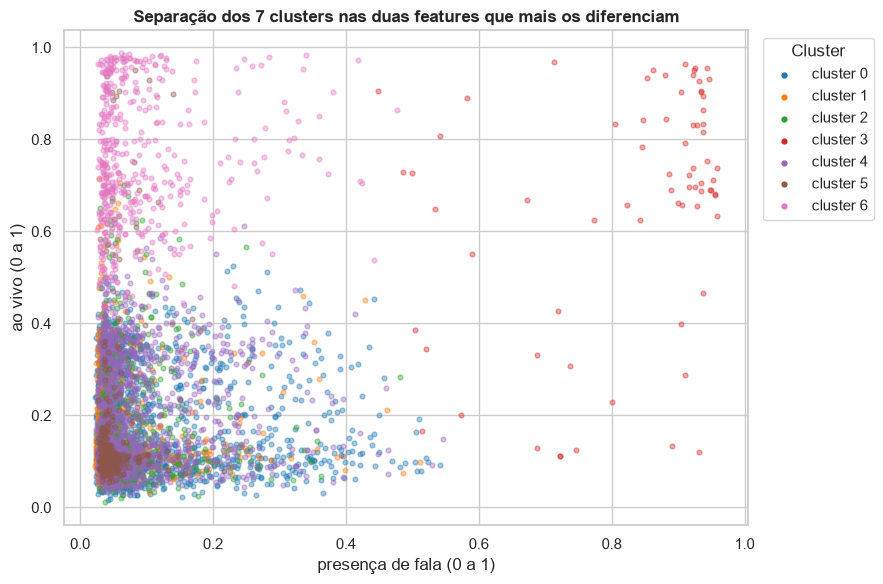

In [29]:
gerador = np.random.default_rng(RANDOM_STATE)
amostra_idx = gerador.choice(len(df_faixas), size=TAMANHO_AMOSTRA_GRAFICOS, replace=False)
amostra = df_faixas.iloc[amostra_idx]

CORES_CLUSTERS = sns.color_palette("tab10", K_ESCOLHIDO)
ROTULOS_PT = {
    "danceability": "dançabilidade (0 a 1)", "energy": "energia (0 a 1)",
    "loudness": "volume (dB)", "speechiness": "presença de fala (0 a 1)",
    "acousticness": "acústica (0 a 1)", "instrumentalness": "instrumental (0 a 1)",
    "liveness": "ao vivo (0 a 1)", "valence": "positividade (0 a 1)", "tempo": "andamento (BPM)",
}

fig, ax = plt.subplots(figsize=(9, 6))
for c in range(K_ESCOLHIDO):
    pontos = amostra[amostra["cluster"] == c]
    ax.scatter(pontos[eixo_x], pontos[eixo_y], s=12, alpha=0.4, color=CORES_CLUSTERS[c],
               label=f"cluster {c}")
ax.set(title=f"Separação dos {K_ESCOLHIDO} clusters nas duas features que mais os diferenciam",
       xlabel=ROTULOS_PT[eixo_x], ylabel=ROTULOS_PT[eixo_y])
legenda = ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
for marcador in legenda.legend_handles:
    marcador.set_alpha(1)
plt.tight_layout()
plt.show()

O gráfico mostra bem **dois** dos sete grupos:

- o **cluster 3 (fala)**, em vermelho, ocupa a direita (presença de fala acima de ≈ 0,6) e se
  espalha de alto a baixo, com muitos pontos no alto, porque boa parte das faixas de comédia é
  gravada com plateia;
- o **cluster 6 (ao vivo)**, em rosa, ocupa o **alto à esquerda**: `liveness` acima de ≈ 0,6 e
  pouca fala.

Os outros cinco grupos ficam **amontoados no canto de baixo à esquerda** (o cluster 0, em azul,
avança um pouco para a direita, com fala moderada): em fala e "ao vivo" eles
são parecidos, e o que os separa são as outras features (energia, acústica, dançabilidade…). Esse
é o limite de qualquer gráfico com 2 das 9 dimensões: nenhum par de features sozinho separa os sete
grupos. A seguir, mais dois pares mostram os outros cinco, e o gráfico da IV.4 combina todas as
features num só plano.

**E os outros cinco grupos?** O que os separa aparece na tabela de centroides da IV.2:
`valence` e `energy` (clusters 0, 1 e 4) e `instrumentalness` e `acousticness` (clusters 1, 2 e 5).
Por isso, desenhamos esses cinco grupos em mais dois pares de features, com as mesmas faixas da
amostra e as mesmas cores. Os grupos que o gráfico anterior já separou ficam de fora: são os que
têm o centroide a mais de 2 desvios-padrão da média em um dos dois eixos.

Já separados no gráfico anterior: [3, 6] · desenhados agora: [0, 1, 2, 4, 5]


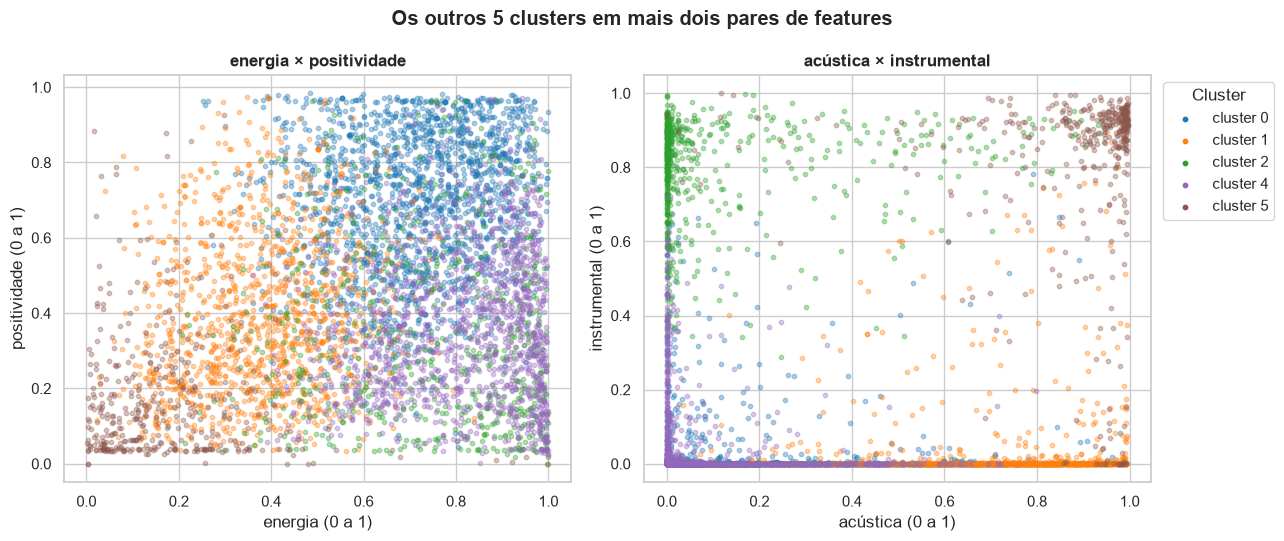

In [30]:
posicao_eixos = [FEATURES.index(eixo_x), FEATURES.index(eixo_y)]
ja_separados = [c for c in range(K_ESCOLHIDO) if centroides_padronizados[c, posicao_eixos].max() > 2]
outros_clusters = [c for c in range(K_ESCOLHIDO) if c not in ja_separados]
print(f"Já separados no gráfico anterior: {ja_separados} · desenhados agora: {outros_clusters}")

PARES_EXTRAS = [("energy", "valence"), ("acousticness", "instrumentalness")]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (fx, fy) in zip(axes, PARES_EXTRAS):
    for c in outros_clusters:
        pontos = amostra[amostra["cluster"] == c]
        ax.scatter(pontos[fx], pontos[fy], s=10, alpha=0.35, color=CORES_CLUSTERS[c],
                   label=f"cluster {c}")
    ax.set(title=f"{ROTULOS_PT[fx].split(' (')[0]} × {ROTULOS_PT[fy].split(' (')[0]}",
           xlabel=ROTULOS_PT[fx], ylabel=ROTULOS_PT[fy])
legenda = axes[1].legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
for marcador in legenda.legend_handles:
    marcador.set_alpha(1)
fig.suptitle(f"Os outros {len(outros_clusters)} clusters em mais dois pares de features",
             fontweight="bold")
plt.tight_layout()
plt.show()

Com esses dois pares, cada um dos cinco grupos ocupa uma região própria em pelo menos um gráfico:

- **energia × positividade**: o cluster 0 (azul) ocupa o alto à direita (energia e positividade
  altas), o cluster 4 (roxo) o canto de baixo à direita (muita energia, pouca positividade), o
  cluster 1 (laranja) a esquerda e o centro (pouca energia) e o cluster 5 (marrom) o canto de baixo
  à esquerda (pouca energia e pouca positividade). O cluster 2 (verde) se mistura com o 4 neste par;
- **acústica × instrumental**: o cluster 2 (verde) sobe pela borda esquerda (instrumental e pouco
  acústico), o cluster 5 (marrom) se concentra no canto de cima à direita (instrumental e acústico)
  e o cluster 1 (laranja) se espalha pela base, à direita (acústico e com voz). Os clusters 0 e 4
  ficam juntos no canto de baixo à esquerda, e quem os separa é o par anterior.

Somando os três gráficos da IV.3, os **sete** grupos aparecem separados. Cada um se destaca numa
combinação diferente das 9 features, e é por isso que nenhum par sozinho mostra todos.

### IV.4 Centroides em relação aos pontos

Para ver **todos** os grupos e seus centroides de uma vez, usamos a **PCA** (Análise de Componentes
Principais). A PCA cria dois novos eixos, chamados **componentes principais**, que são combinações
das 9 features escolhidas para preservar o máximo possível da variação dos dados. É como achar o
ângulo de foto que mostra melhor um objeto 3D numa imagem 2D.

O código:

1. ajusta a PCA em todas as faixas de `X` (`fit`);
2. projeta a mesma amostra da IV.3 e os 7 centroides nesses dois eixos (`transform`);
3. mostra quanto cada feature pesa em cada componente, para que os eixos possam ser lidos.

In [31]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
pontos_2d = pca.transform(X[amostra_idx])
centroides_2d = pca.transform(centroides_padronizados)
variancia = pca.explained_variance_ratio_

print(f"Variância explicada: PC1 {variancia[0]:.1%} + PC2 {variancia[1]:.1%} = {variancia.sum():.1%}")
pd.DataFrame(pca.components_, columns=FEATURES, index=["PC1", "PC2"]).round(2)

Variância explicada: PC1 31.9% + PC2 16.0% = 47.9%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.25,0.51,0.52,0.10,-0.44,-0.28,0.09,0.30,0.19
PC2,0.57,-0.28,-0.08,0.04,0.31,-0.32,-0.21,0.53,-0.28


Os dois componentes guardam **47,9%** da variação das 9 features (31,9% + 16,0%). Os pesos dão
sentido aos eixos:

- **PC1** pesa positivo em `energy` (+0,51) e `loudness` (+0,52) e negativo em `acousticness`
  (−0,44). É um eixo de **intensidade**: à direita, faixas altas e enérgicas; à esquerda, calmas e
  acústicas.
- **PC2** pesa positivo em `danceability` (+0,57) e `valence` (+0,53). É um eixo de **dança e
  alegria**.

Repare que `speechiness` (+0,10 e +0,04) e `liveness` (+0,09 e −0,21) pesam pouco nesses eixos.

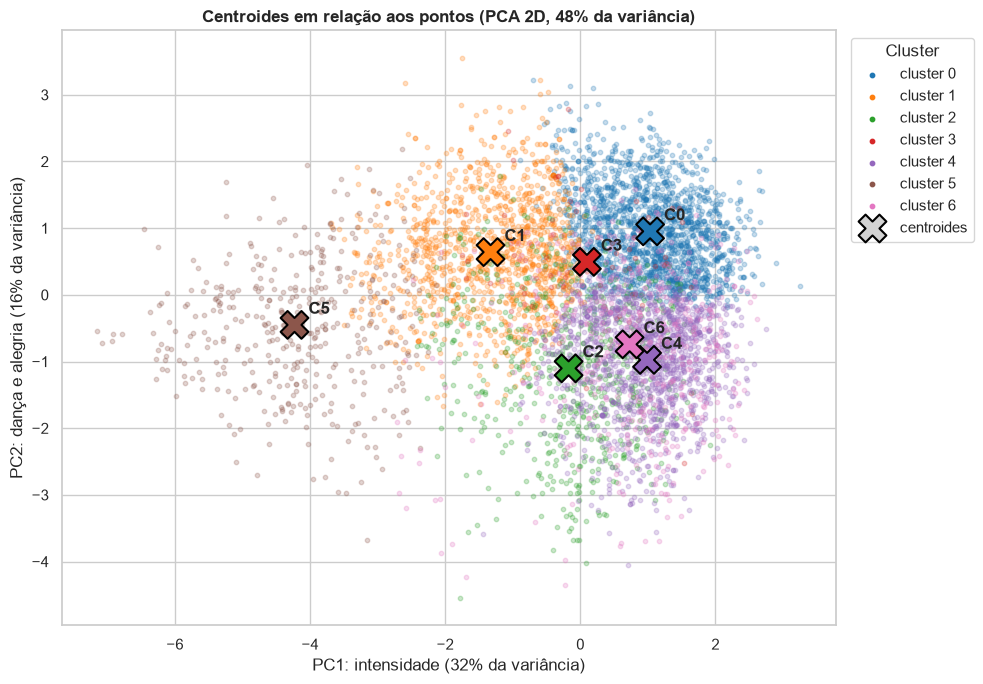

In [32]:
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(K_ESCOLHIDO):
    selecao = rotulos[amostra_idx] == c
    ax.scatter(pontos_2d[selecao, 0], pontos_2d[selecao, 1], s=10, alpha=0.25,
               color=CORES_CLUSTERS[c], label=f"cluster {c}")
ax.scatter(centroides_2d[:, 0], centroides_2d[:, 1], marker="X", s=400, color=CORES_CLUSTERS,
           edgecolor="black", linewidth=1.5, zorder=3, label="centroides")
for c, (x, y) in enumerate(centroides_2d):
    ax.annotate(f"C{c}", (x, y), xytext=(10, 8), textcoords="offset points",
                fontsize=12, fontweight="bold")
ax.set(title=f"Centroides em relação aos pontos (PCA 2D, {variancia.sum():.0%} da variância)",
       xlabel=f"PC1: intensidade ({variancia[0]:.0%} da variância)",
       ylabel=f"PC2: dança e alegria ({variancia[1]:.0%} da variância)")
legenda = ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
for marcador in legenda.legend_handles[:-1]:
    marcador.set_alpha(1)
legenda.legend_handles[-1].set_facecolor("lightgray")  # o "X" da legenda não é de nenhum cluster
plt.tight_layout()
plt.show()

Cada **X** é um centroide, na mesma cor dos pontos do seu grupo:

- **C5 (ambiente/clássico)** fica isolado na extrema esquerda (PC1 ≈ −4,2): é o grupo menos
  intenso;
- **C0 (alegre e dançante)** fica em cima à direita (≈ 1,0 ; 0,9): intenso e dançante;
- **C4 (intenso)** fica embaixo à direita (≈ 1,0 ; −1,0): intenso, mas pouco dançante;
- **C1 (acústico e calmo)** fica à esquerda e acima (≈ −1,3 ; 0,6);
- **C2 (instrumental enérgico)** fica embaixo no centro (≈ −0,2 ; −1,1).

**C3 (fala)** cai **perto do centro** (≈ 0,1 ; 0,5) e **C6 (ao vivo)** fica **quase em cima de C4**
(≈ 0,7 ; −0,7), misturados aos outros grupos. Não é um erro do K-Means: o que separa esses dois grupos é `speechiness` e `liveness`, justamente as features que
quase não pesam nos dois componentes. O gráfico da IV.3 mostra esses dois bem separados. Os dois
gráficos se complementam, e juntos eles lembram que **47,9% da variação cabe no plano**; o resto
fica nas outras dimensões.

#### 🧪 Experimente: com e sem padronização

Na III.5 vimos, com duas faixas, que sem padronizar `tempo` e `loudness` dominam a distância. E o
agrupamento inteiro? A célula abaixo treina um K-Means com k = 7 nas features **na escala
original** (`USAR_PADRONIZACAO = False`) e mostra os centroides, ordenados por `tempo`.

Depois troque para `True` e rode de novo: o modelo usa `X` e reproduz exatamente os grupos da
IV.2. Compare a última linha da saída (a concordância com o modelo padronizado) nos dois casos.

A concordância é medida pelo **ARI** (*Adjusted Rand Index*), que compara dois agrupamentos
ignorando a numeração dos grupos: 1 = idênticos, 0 = tão parecidos quanto dois agrupamentos
sorteados ao acaso.

In [33]:
USAR_PADRONIZACAO = False  # ✏️ troque para True e rode de novo

dados_treino = X if USAR_PADRONIZACAO else df_faixas[FEATURES].to_numpy()
modelo_exp = KMeans(n_clusters=K_ESCOLHIDO, n_init=10, random_state=RANDOM_STATE).fit(dados_treino)

centros_exp = modelo_exp.cluster_centers_
if USAR_PADRONIZACAO:
    centros_exp = scaler.inverse_transform(centros_exp)  # volta para BPM, dB etc.
centros_exp = pd.DataFrame(centros_exp, columns=FEATURES)
centros_exp.insert(0, "faixas", np.bincount(modelo_exp.labels_))
centros_exp = centros_exp.sort_values("tempo").rename_axis("cluster")

amplitude = centros_exp[FEATURES].max() - centros_exp[FEATURES].min()
ari = adjusted_rand_score(rotulos, modelo_exp.labels_)

print(f"Treino {'COM' if USAR_PADRONIZACAO else 'SEM'} padronização: centroides na escala original")
display(centros_exp.round(2))
print("Diferença entre o maior e o menor centroide, por feature:")
print(amplitude.round(2).to_string())
print(f"\nConcordância com o modelo padronizado da IV.2 (ARI): {ari:.3f}")

Treino SEM padronização: centroides na escala original


,faixas,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,,
0,10257,0.46,0.44,-12.19,0.11,0.57,0.25,0.22,0.36,76.75
4,15419,0.59,0.63,-8.13,0.09,0.34,0.13,0.22,0.49,94.56
2,13019,0.60,0.62,-8.75,0.08,0.36,0.15,0.22,0.49,109.79
6,20474,0.63,0.67,-8.14,0.07,0.26,0.21,0.20,0.48,124.90
5,12943,0.56,0.65,-8.28,0.08,0.31,0.17,0.22,0.46,139.47
1,8833,0.52,0.73,-6.84,0.09,0.24,0.12,0.23,0.50,155.84
3,8638,0.48,0.71,-7.02,0.11,0.25,0.16,0.21,0.48,178.42


Diferença entre o maior e o menor centroide, por feature:
danceability          0.18
energy                0.29
loudness              5.35
speechiness           0.04
acousticness          0.33
instrumentalness      0.13
liveness              0.03
valence               0.14
tempo               101.67

Concordância com o modelo padronizado da IV.2 (ARI): 0.039


Com `USAR_PADRONIZACAO = False` (o valor original), o resultado confirma a III.5 em escala real:

- Os centroides vão de **76,8 a 178,4 BPM**: uma diferença de **101,7 BPM** entre o grupo mais
  lento e o mais rápido. `loudness` vem em segundo, com 5,4 dB.
- Nas outras features, os centroides quase não mudam de um grupo para outro: `speechiness` varia
  só **0,04** e `liveness` **0,03**. O grupo da fala e o grupo ao vivo simplesmente desaparecem.
- Os 7 grupos viraram **7 faixas de andamento**: o K-Means sem padronização agrupa músicas pela
  velocidade, não pelo som como um todo.
- O ARI de **0,039** mostra que esse agrupamento não tem quase nada a ver com o do modelo
  padronizado.

É por isso que o `StandardScaler` vem antes do K-Means. Com `True`, o ARI vira 1,000, porque o
modelo é o mesmo da IV.2.

## V. Análise e conclusão

### V.1 Perfil de cada cluster

Os centroides da Seção IV estão na escala padronizada ("desvios da média"), boa para o K-Means
mas difícil de ler. O enunciado pede para interpretar os grupos **com base no dataset original**,
então usamos o `scaler` guardado na III.5 para fazer a conta inversa da padronização
(`inverse_transform`: x = z × desvio + média). Assim cada centroide volta para as unidades reais:
dançabilidade de 0 a 1, volume em dB, andamento em BPM.

`perfil_clusters` junta o tamanho de cada grupo e o seu centroide na escala original. A última
linha da tabela mostra a média de todas as faixas, para comparação.

In [34]:
centroides_originais = pd.DataFrame(
    scaler.inverse_transform(centroides_padronizados), columns=FEATURES
).rename_axis("cluster")

perfil_clusters = centroides_originais.copy()
perfil_clusters.insert(0, "faixas", np.bincount(rotulos))
perfil_clusters.insert(1, "% do total", (100 * perfil_clusters["faixas"] / len(rotulos)).round(1))

media_geral = df_faixas[FEATURES].mean().to_frame("média de todas").T
pd.concat([perfil_clusters, media_geral]).round(3).astype({"faixas": "Int64"})

,faixas,% do total,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,27523,30.7,0.706,0.716,-6.555,0.096,0.221,0.020,0.164,0.697,117.701
1,18082,20.2,0.526,0.375,-10.644,0.054,0.686,0.032,0.160,0.393,113.232
2,10094,11.3,0.584,0.741,-8.464,0.072,0.114,0.795,0.170,0.345,126.826
3,1045,1.2,0.572,0.675,-11.232,0.845,0.746,0.007,0.668,0.442,100.907
4,20162,22.5,0.472,0.817,-5.339,0.086,0.077,0.037,0.195,0.376,140.738
5,6464,7.2,0.350,0.171,-21.258,0.052,0.869,0.786,0.157,0.185,104.798
6,6213,6.9,0.520,0.752,-7.106,0.088,0.291,0.077,0.744,0.504,123.294
média de todas,<NA>,NaN,0.563,0.635,-8.475,0.088,0.328,0.173,0.217,0.470,122.272


Agora os números falam a língua da música. Alguns destaques, comparando com a última linha:

- o **cluster 5** tem volume médio de **−21,3 dB**, contra −8,5 dB da média, e `energy` de só
  **0,17** (média 0,64);
- o **cluster 4** é o mais alto (**−5,3 dB**) e o mais rápido (**141 BPM**, contra 122);
- o **cluster 3** tem `speechiness` de **0,85**, quase dez vezes a média (0,09);
- o **cluster 6** tem `liveness` de **0,74**, mais de três vezes a média (0,22).

Uma tabela com 9 colunas é difícil de comparar de relance. O **mapa de calor** abaixo mostra os
mesmos centroides na escala padronizada, em que as features ficam comparáveis entre si:
**vermelho** = acima da média, **azul** = abaixo, branco = na média.

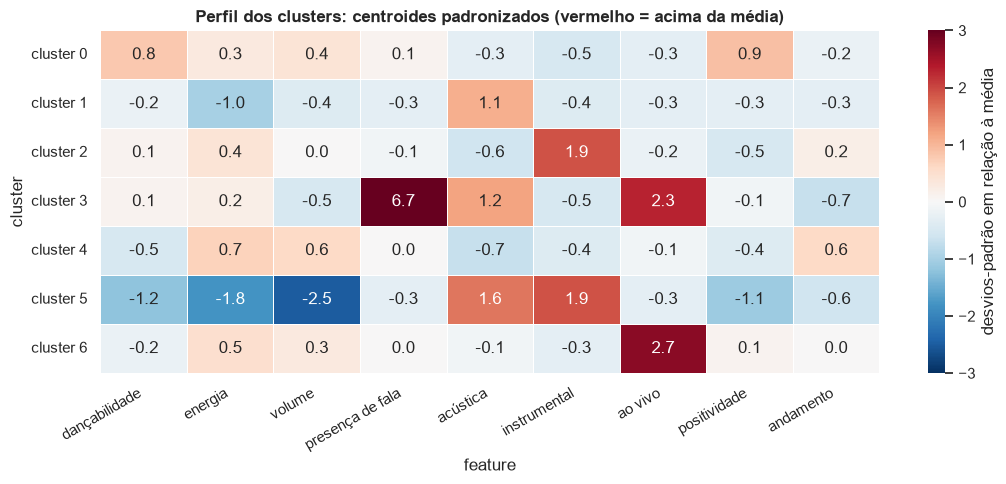

In [35]:
NOMES_FEATURES_PT = {f: ROTULOS_PT[f].split(" (")[0] for f in FEATURES}  # "dançabilidade", "volume"...
mapa = pd.DataFrame(centroides_padronizados, columns=[NOMES_FEATURES_PT[f] for f in FEATURES])
mapa = mapa.round(1) + 0.0  # troca o -0,0 por 0,0 nos rótulos
mapa.index = [f"cluster {c}" for c in range(K_ESCOLHIDO)]

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(mapa, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3, vmax=3,
            linewidths=0.5, cbar_kws={"label": "desvios-padrão em relação à média"}, ax=ax)
ax.set(title="Perfil dos clusters: centroides padronizados (vermelho = acima da média)",
       xlabel="feature", ylabel="cluster")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Cada linha do mapa é a "impressão digital" de um grupo:

- **cluster 0**: vermelho em dançabilidade (+0,8) e positividade (+0,9);
- **cluster 1**: vermelho em acústica (+1,1) e azul em energia (−1,0);
- **cluster 2**: vermelho forte em instrumental (+1,9), com energia acima da média (+0,4);
- **cluster 3**: o vermelho mais intenso do mapa, em presença de fala (+6,7, bem além do limite
  da escala de cores), e também em ao vivo (+2,3);
- **cluster 4**: vermelho em energia (+0,7), volume (+0,6) e andamento (+0,6), azul em acústica
  (−0,7);
- **cluster 5**: a linha mais azul (volume −2,5, energia −1,8, dançabilidade −1,2, positividade
  −1,1) e vermelha em acústica (+1,6) e instrumental (+1,9);
- **cluster 6**: vermelho forte em ao vivo (+2,7) e quase branco no resto.

**Contexto.** `popularity`, `duration_ms` e `explicit` não entraram no treino, mas ajudam a
interpretar os grupos:

In [36]:
contexto = df_faixas.groupby("cluster").agg(
    popularidade_media=("popularity", "mean"),
    duracao_media_min=("duration_ms", lambda ms: ms.mean() / 60_000),
    pct_explicitas=("explicit", lambda e: 100 * e.mean()),
)
contexto.round(1)

,popularidade_media,duracao_media_min,pct_explicitas
cluster,,,
0,34.5,3.6,12.7
1,33.5,3.6,3.9
2,27.3,4.7,3.6
3,24.6,3.7,56.3
4,35.5,3.9,10.6
5,28.5,3.7,0.3
6,35.0,4.0,6.1


- o **cluster 3** tem **56%** de faixas com conteúdo explícito, contra 0% a 13% nos outros, o que
  combina com *stand-up* e falas sem censura;
- o **cluster 2** tem as faixas mais longas (**4,7 min** em média), comum na música eletrônica;
- a popularidade média fica entre 24,6 e 35,5 em todos os grupos: o K-Means não separou "sucessos" de
  "faixas desconhecidas", o que é esperado, já que a popularidade não entrou no treino.

### V.2 Dando nome aos grupos

Com o perfil em mãos, cada grupo ganha um nome. A regra (constituição V) é que **todo nome cite os
valores que o justificam**, sempre comparados com a média de todas as faixas (entre parênteses):

| Cluster | Nome | Valores que justificam (média geral) |
|---|---|---|
| 0 | **Dançante e alegre** | dançabilidade 0,71 (0,56) · positividade 0,70 (0,47) · energia 0,72 (0,64) · instrumental 0,02 (0,17) |
| 1 | **Acústico e calmo** | acústica 0,69 (0,33) · energia 0,38 (0,64) · volume −10,6 dB (−8,5) |
| 2 | **Instrumental enérgico** | instrumental 0,80 (0,17) · energia 0,74 (0,64) · acústica 0,11 (0,33) |
| 3 | **Fala e comédia** | presença de fala 0,85 (0,09) · ao vivo 0,67 (0,22) · 56% explícitas |
| 4 | **Intenso e pesado** | energia 0,82 (0,64) · volume −5,3 dB (−8,5) · andamento 141 BPM (122) · acústica 0,08 (0,33) |
| 5 | **Ambiente e clássico** | volume −21,3 dB (−8,5) · energia 0,17 (0,64) · instrumental 0,79 (0,17) · acústica 0,87 (0,33) |
| 6 | **Ao vivo** | ao vivo 0,74 (0,22) · energia 0,75 (0,64) · presença de fala 0,09 (0,09: é música, não comédia) |

Os números dos clusters (0 a 6) são sempre os mesmos porque a semente `RANDOM_STATE` é fixa. Com
outra semente, os mesmos grupos apareceriam com outra numeração.

In [37]:
NOMES_CLUSTERS = {
    0: "Dançante e alegre",
    1: "Acústico e calmo",
    2: "Instrumental enérgico",
    3: "Fala e comédia",
    4: "Intenso e pesado",
    5: "Ambiente e clássico",
    6: "Ao vivo",
}
perfil_clusters["nome"] = perfil_clusters.index.map(NOMES_CLUSTERS)
perfil_clusters[["nome", "faixas", "% do total"]]

,nome,faixas,% do total
cluster,,,
0,Dançante e alegre,27523,30.7
1,Acústico e calmo,18082,20.2
2,Instrumental enérgico,10094,11.3
3,Fala e comédia,1045,1.2
4,Intenso e pesado,20162,22.5
5,Ambiente e clássico,6464,7.2
6,Ao vivo,6213,6.9


**Exemplos de faixas.** Para cada grupo, buscamos faixas **típicas**: as 300 mais próximas do
centroide (as que mais se parecem com o "ponto médio" do grupo). Entre elas, mostramos as 3 mais
populares, para que os exemplos sejam ao mesmo tempo representativos e conhecidos. Pegar só as
mais populares de cada grupo não serviria, porque elas podem estar na borda do grupo, longe do
perfil típico.

In [38]:
distancia_ao_centroide = np.linalg.norm(X - centroides_padronizados[rotulos], axis=1)

linhas = []
for c in range(K_ESCOLHIDO):
    do_cluster = df_faixas[rotulos == c].assign(distancia=distancia_ao_centroide[rotulos == c])
    tipicas = do_cluster.nsmallest(300, "distancia")
    exemplos = (tipicas.sort_values("popularity", ascending=False, kind="stable")
                .drop_duplicates(["track_name", "artists"]).head(3))
    for _, faixa in exemplos.iterrows():
        linhas.append({"cluster": f"{c} · {NOMES_CLUSTERS[c]}", "faixa": faixa["track_name"],
                       "artista": faixa["artists"].replace(";", ", "),
                       "popularidade": faixa["popularity"]})
pd.DataFrame(linhas).set_index("cluster")

,faixa,artista,popularidade
cluster,,,
0 · Dançante e alegre,Bad Memories (feat. Elley Duhé & FAST BOY),"MEDUZA, James Carter, Elley Duhé, FAST BOY",85
0 · Dançante e alegre,Have You Ever Seen The Rain,Creedence Clearwater Revival,84
0 · Dançante e alegre,Fortunate Son,Creedence Clearwater Revival,82
1 · Acústico e calmo,Ivy,Frank Ocean,81
1 · Acústico e calmo,Beautiful Crazy,Luke Combs,80
1 · Acústico e calmo,Your Song,Elton John,79
2 · Instrumental enérgico,She Sells Sanctuary,The Cult,71
2 · Instrumental enérgico,Children,Robert Miles,69
2 · Instrumental enérgico,Come With Me - Radio Mix,Nora En Pure,64


Os exemplos combinam com os nomes:

- **Dançante e alegre**: "Have You Ever Seen The Rain" e "Fortunate Son" (Creedence Clearwater
  Revival), músicas animadas e fáceis de acompanhar;
- **Acústico e calmo**: "Your Song" (Elton John) e "Beautiful Crazy" (Luke Combs), baladas
  acústicas;
- **Instrumental enérgico**: "Children" (Robert Miles), um clássico da música eletrônica
  instrumental;
- **Fala e comédia**: uma história da Peppa Pig e um "Poema - En Vivo" (Joan Sebastian): faixas
  faladas;
- **Intenso e pesado**: "Thunderstruck" (AC/DC);
- **Ambiente e clássico**: "Day Dream" (Bill Charlap Trio) e faixas calmas como "Poison Tree"
  (Grouper);
- **Ao vivo**: "The Passenger" (Iggy Pop), "Dollhouse" (Melanie Martinez) e "Tell It To My Heart".

Nem todo exemplo é perfeito, e aqui aparecem dois casos. "She Sells Sanctuary" (The Cult) tem vocal
do começo ao fim, mas caiu no grupo instrumental. E as três faixas do grupo *Ao vivo* são gravações
de estúdio, para as quais o Spotify estimou uma presença de plateia alta. Os números do Spotify são
estimativas feitas por algoritmo, e não rótulos humanos, e os erros da estimativa passam para os
grupos. Voltaremos a isso nas limitações (V.4).

#### Simulador: em que grupo cairia a sua música?

Com os 7 grupos nomeados, dá para fazer a pergunta ao contrário: dada uma música qualquer, em que
grupo ela cairia? É o que o `modelo.predict` faz, em dois passos:

1. **padronizar** os 9 valores com a média e o desvio-padrão guardados no `scaler` (III.5);
2. calcular a **distância** até cada um dos 7 centroides e ficar com o mais próximo (o passo de
   atribuição da I.3).

O simulador logo abaixo faz essa conta no navegador. Antes, conferimos em Python que a mesma conta
dá o mesmo grupo que o `modelo.predict` em todas as faixas, e separamos os dados que o simulador
recebe: a média e o desvio de cada feature, os centroides, os nomes e uma faixa típica de cada
grupo.

In [39]:
# A conta do simulador, feita em Python para todas as faixas: padronizar com o scaler e achar o
# centroide mais próximo. Tem que dar o mesmo grupo que o modelo.predict.
padronizadas = (df_faixas[FEATURES].to_numpy() - scaler.mean_) / scaler.scale_
distancias = np.linalg.norm(
    padronizadas[:, np.newaxis, :] - centroides_padronizados[np.newaxis, :, :], axis=2
)
iguais = (distancias.argmin(axis=1) == modelo.predict(X)).mean()
n_faixas = f"{len(df_faixas):,}".replace(",", ".")
pct_iguais = f"{100 * iguais:.1f}".replace(".", ",")
print(f"A conta do simulador dá o mesmo grupo que o modelo.predict em {pct_iguais}% "
      f"das {n_faixas} faixas")

# Dados que o simulador recebe: escala de cada controle, média e desvio do scaler, centroides,
# nomes, cores e uma faixa típica de cada grupo (a mais popular entre as 300 mais próximas do
# centroide, como na tabela de exemplos acima).
controles_simulador = []
for f in FEATURES:
    if f in ("loudness", "tempo"):
        unidade, passo, casas = ("dB", 0.1, 1) if f == "loudness" else ("BPM", 0.1, 0)
        minimo, maximo = np.floor(df_faixas[f].min()), np.ceil(df_faixas[f].max())
    else:
        unidade, passo, casas, minimo, maximo = "", 0.001, 2, 0, 1
    controles_simulador.append({"nome": NOMES_FEATURES_PT[f], "unidade": unidade, "min": float(minimo),
                                "max": float(maximo), "passo": passo, "casas": casas})

exemplos_simulador = []
for c in range(K_ESCOLHIDO):
    do_cluster = df_faixas[rotulos == c].assign(distancia=distancia_ao_centroide[rotulos == c])
    faixa_tipica = (do_cluster.nsmallest(300, "distancia")
             .sort_values("popularity", ascending=False, kind="stable").iloc[0])
    exemplos_simulador.append({
        "rotulo": f'{faixa_tipica["track_name"]} — {faixa_tipica["artists"].split(";")[0]} · cluster {c}',
        "valores": [round(float(faixa_tipica[f]), 3) for f in FEATURES],
    })

dados_simulador = {
    "features": controles_simulador,
    "media": scaler.mean_.tolist(),
    "escala": scaler.scale_.tolist(),
    "centroides": centroides_padronizados.tolist(),
    "nomes": [NOMES_CLUSTERS[c] for c in range(K_ESCOLHIDO)],
    "cores": CORES_CLUSTERS.as_hex(),
    "exemplos": exemplos_simulador,
}
print("Faixas de exemplo no simulador:")
for exemplo in exemplos_simulador:
    print("  -", exemplo["rotulo"])


A conta do simulador dá o mesmo grupo que o modelo.predict em 100,0% das 89.583 faixas
Faixas de exemplo no simulador:
  - Bad Memories (feat. Elley Duhé & FAST BOY) — MEDUZA · cluster 0
  - Ivy — Frank Ocean · cluster 1
  - She Sells Sanctuary — The Cult · cluster 2
  - Mr. Bull’s New Road — Peppa Pig Stories · cluster 3
  - Thunderstruck — AC/DC · cluster 4
  - Poison Tree — Grouper · cluster 5
  - Tell It To My Heart — MEDUZA · cluster 6


A conta bate em **100,0%** das faixas, então o simulador é fiel ao modelo. As 7 faixas de exemplo
são as primeiras de cada grupo na tabela de exemplos acima.

In [40]:
# @title Simulador: em que grupo cairia a sua música? (clique duas vezes para ver o código)
# HTML, CSS e JavaScript puro, sem bibliotecas externas (FR-008). Os dados vêm de dados_simulador.
HTML_GRUPO = r'''<div id="km-grupo">
<style>
#km-grupo{--fundo:#ffffff;--cartao:#f6f7f9;--borda:#d7dbe0;--texto:#1f2328;--fraco:#5c6570;--acento:#1a73e8;
  font-family:"Google Sans","Segoe UI",Roboto,Arial,sans-serif;color:var(--texto);background:var(--fundo);
  border:1px solid var(--borda);border-radius:16px;padding:18px;max-width:900px;box-sizing:border-box;line-height:1.4}
#km-grupo *{box-sizing:border-box}
#km-grupo h3{margin:0 0 2px;font-size:19px;font-weight:600}
#km-grupo .sub{color:var(--fraco);font-size:13px;margin-bottom:12px}
#km-grupo .topo{display:flex;flex-wrap:wrap;gap:8px;align-items:center;margin-bottom:12px;font-size:13px}
#km-grupo select{border:1px solid var(--borda);border-radius:8px;padding:6px 8px;font:inherit;font-size:13px;background:#fff;color:var(--texto);max-width:100%}
#km-grupo .grade{display:flex;flex-wrap:wrap;gap:16px}
#km-grupo .controles{flex:1 1 330px;display:flex;flex-direction:column;gap:7px}
#km-grupo .resultado{flex:1 1 330px;display:flex;flex-direction:column;gap:10px}
#km-grupo .ctl{display:grid;grid-template-columns:120px 1fr 78px;gap:8px;align-items:center;font-size:13px}
#km-grupo .ctl span.val{text-align:right;font-variant-numeric:tabular-nums;font-weight:600}
#km-grupo input[type=range]{width:100%;accent-color:var(--acento)}
#km-grupo .cartao{background:var(--cartao);border:1px solid var(--borda);border-radius:12px;padding:10px 12px}
#km-grupo .grupo{border-left:8px solid #999}
#km-grupo .grupo .rotulo{font-size:12px;color:var(--fraco)}
#km-grupo .grupo .nome{font-size:22px;font-weight:600}
#km-grupo .barra{display:grid;grid-template-columns:150px 1fr 44px;gap:8px;align-items:center;font-size:12.5px;margin:3px 0}
#km-grupo .barra .trilho{background:#e6e8eb;border-radius:999px;height:12px;overflow:hidden}
#km-grupo .barra .preench{height:100%;border-radius:999px}
#km-grupo .barra.perto{font-weight:600}
#km-grupo .barra span.num{text-align:right;font-variant-numeric:tabular-nums}
#km-grupo .chips{display:flex;flex-wrap:wrap;gap:5px;margin-top:4px}
#km-grupo .chip{border-radius:999px;padding:2px 9px;font-size:12px;font-variant-numeric:tabular-nums;border:1px solid var(--borda)}
#km-grupo .nota{font-size:12px;color:var(--fraco)}
</style>
<h3>Simulador: em que grupo cairia a sua música?</h3>
<div class="sub">Mova os controles para descrever uma música. O simulador faz a mesma conta do <code>modelo.predict</code>: padroniza os 9 valores com a média e o desvio do <code>scaler</code> e procura o centroide mais próximo entre os 7.</div>
<div class="topo">Começar de: <select data-id="exemplo"></select></div>
<div class="grade">
  <div class="controles" data-id="controles"></div>
  <div class="resultado">
    <div class="cartao grupo" data-id="cartao">
      <div class="rotulo">grupo mais próximo</div>
      <div class="nome" data-id="nome">–</div>
      <div class="nota" data-id="detalhe"></div>
    </div>
    <div class="cartao">
      <div class="nota" style="margin-bottom:4px">Distância até o centroide de cada grupo (menor = mais parecido)</div>
      <div data-id="barras"></div>
    </div>
    <div class="cartao">
      <div class="nota">A sua música padronizada: quantos desvios-padrão cada valor está acima (+) ou abaixo (−) da média das 89 mil faixas</div>
      <div class="chips" data-id="chips"></div>
    </div>
  </div>
</div>
<script>
(function () {
  const D = __DADOS__;
  const raiz = document.currentScript.parentElement;
  const el = id => raiz.querySelector('[data-id="' + id + '"]');
  const fmt = (v, c) => v.toLocaleString("pt-BR", {minimumFractionDigits: c, maximumFractionDigits: c}).replace("-", "−");
  const sinal = v => {
    const r = Math.round(v * 10) / 10;
    return r === 0 ? "0,0" : (r > 0 ? "+" : "−") + fmt(Math.abs(r), 1);
  };
  const controles = [];

  D.features.forEach((f, i) => {
    const linha = document.createElement("div");
    linha.className = "ctl";
    linha.innerHTML = '<span>' + f.nome + '</span><input type="range" min="' + f.min + '" max="' + f.max +
      '" step="' + f.passo + '"><span class="val"></span>';
    el("controles").appendChild(linha);
    const entrada = linha.querySelector("input");
    entrada.addEventListener("input", calcular);
    controles.push({entrada, valor: linha.querySelector(".val"), f});
  });

  const sel = el("exemplo");
  sel.add(new Option("Média de todas as faixas", "media"));
  D.exemplos.forEach((ex, i) => sel.add(new Option(ex.rotulo, String(i))));
  sel.onchange = () => carregar(sel.value === "media" ? D.media : D.exemplos[Number(sel.value)].valores);

  function carregar(valores) {
    controles.forEach((c, i) => { c.entrada.value = valores[i]; });
    calcular();
  }

  function calcular() {
    const x = controles.map(c => Number(c.entrada.value));
    controles.forEach((c, i) => {
      c.valor.textContent = fmt(x[i], c.f.casas) + (c.f.unidade ? " " + c.f.unidade : "");
    });
    const z = x.map((v, i) => (v - D.media[i]) / D.escala[i]);          // padronização (III.5)
    const dist = D.centroides.map(c => Math.sqrt(c.reduce((s, cj, j) => s + (z[j] - cj) ** 2, 0)));
    let melhor = 0;
    dist.forEach((d, j) => { if (d < dist[melhor]) melhor = j; });     // centroide mais próximo (predict)

    el("nome").textContent = D.nomes[melhor];
    el("detalhe").textContent = "cluster " + melhor + " · distância " + fmt(dist[melhor], 2);
    el("cartao").style.borderLeftColor = D.cores[melhor];

    const maior = Math.max(...dist);
    el("barras").innerHTML = dist.map((d, j) =>
      '<div class="barra' + (j === melhor ? " perto" : "") + '"><span>' + j + " · " + D.nomes[j] +
      '</span><div class="trilho"><div class="preench" style="width:' + (100 * d / maior).toFixed(1) +
      '%;background:' + D.cores[j] + (j === melhor ? "" : "99") + '"></div></div><span class="num">' + fmt(d, 2) + "</span></div>"
    ).join("");

    el("chips").innerHTML = z.map((v, i) => {
      const forte = Math.min(Math.abs(v) / 3, 1);
      const cor = Math.round(v * 10) === 0 ? "#eef0f2" : v >= 0 ? "rgba(214,39,40," + (0.12 + 0.5 * forte) + ")" : "rgba(31,119,180," + (0.12 + 0.5 * forte) + ")";
      return '<span class="chip" style="background:' + cor + '">' + D.features[i].nome + " " + sinal(v) + "</span>";
    }).join("");
  }

  carregar(D.media);
})();
</script>
</div>
'''

display(HTML(HTML_GRUPO.replace("__DADOS__", json.dumps(dados_simulador))))


Experimente no simulador:

- **A música "média"**, o ponto de partida, com todas as features na média, cai em *Dançante e
  alegre*, mas quase empatada com *Intenso e pesado* (distâncias 1,44 e 1,55). É a sobreposição
  entre grupos que a silhueta baixa já indicava (IV.1).
- **Carregue "Thunderstruck"** e baixe a **energia** para 0,20: a faixa continua em *Intenso e
  pesado*, porque o volume e o andamento ainda puxam para lá. Suba também a **acústica** para 0,80,
  e ela passa para *Acústico e calmo*. Mudar uma feature só raramente basta: o grupo depende da
  combinação das 9.
- **Olhe os valores padronizados** (os quadrinhos coloridos). Subir o andamento em 10 BPM muda o
  valor padronizado em cerca de 0,3, enquanto subir a presença de fala em 0,1 muda em cerca de
  0,9. Sem a padronização, os 10 BPM pesariam 100 vezes mais que o 0,1 de fala na distância. É o
  motivo da III.5, agora visto de perto.

### V.3 Clusters × gêneros (com destaque para a música brasileira)

Agora usamos `track_genre`, que ficou **fora do treino** de propósito (III.4). Se os grupos que o
K-Means encontrou só olhando o som fizerem sentido musical, gêneros parecidos devem cair nos
mesmos grupos.

1. Cada faixa de `df_faixas` tem o seu cluster. Um *merge* (junção de tabelas pela coluna
   `track_id`) leva esse rótulo para **todas** as linhas de `df_pares`. Uma faixa que está em `mpb`
   e em `brazil` conta nos dois gêneros, como prometido na III.3.
2. `genero_x_cluster` é uma tabela cruzada (*crosstab*) **normalizada por gênero**: cada linha diz
   que fração das faixas daquele gênero caiu em cada cluster (cada linha soma 1).

In [41]:
df_pares = (df_pares.drop(columns="cluster", errors="ignore")  # permite rodar a célula de novo
            .merge(df_faixas[["track_id", "cluster"]], on="track_id", how="left"))
assert df_pares["cluster"].notna().all(), "toda faixa de df_pares deveria ter um cluster"

genero_x_cluster = pd.crosstab(df_pares["track_genre"], df_pares["cluster"], normalize="index")
contagem = pd.crosstab(df_pares["track_genre"], df_pares["cluster"])

top_generos = {}
for c in range(K_ESCOLHIDO):
    principais = contagem[c].nlargest(5).index
    top_generos[f"{c} · {NOMES_CLUSTERS[c]}"] = [
        f"{g} ({100 * genero_x_cluster.loc[g, c]:.0f}%)" for g in principais
    ]
n_pares = f"{len(df_pares):,}".replace(",", ".")
print(f"df_pares: {n_pares} pares, todos com cluster")
cluster_fala = next(c for c, nome in NOMES_CLUSTERS.items() if nome == "Fala e comédia")
pct_comedy = 100 * contagem.loc["comedy", cluster_fala] / contagem[cluster_fala].sum()
print(f"{pct_comedy:.0f}% das faixas do cluster Fala e comédia são do gênero comedy")
print("Os 5 gêneros com mais faixas em cada cluster (entre parênteses: % do gênero que caiu ali)")
pd.DataFrame(top_generos, index=[f"{i}º" for i in range(1, 6)]).T

df_pares: 113.392 pares, todos com cluster
75% das faixas do cluster Fala e comédia são do gênero comedy
Os 5 gêneros com mais faixas em cada cluster (entre parênteses: % do gênero que caiu ali)


,1º,2º,3º,4º,5º
0 · Dançante e alegre,reggaeton (85%),dancehall (84%),latino (83%),reggae (83%),salsa (80%)
1 · Acústico e calmo,tango (78%),honky-tonk (76%),jazz (72%),romance (77%),cantopop (69%)
2 · Instrumental enérgico,minimal-techno (86%),detroit-techno (76%),techno (62%),study (60%),grindcore (53%)
3 · Fala e comédia,comedy (81%),show-tunes (3%),children (2%),kids (2%),funk (2%)
4 · Intenso e pesado,metalcore (85%),grunge (72%),heavy-metal (72%),metal (72%),dubstep (71%)
5 · Ambiente e clássico,new-age (78%),classical (74%),ambient (66%),sleep (73%),piano (56%)
6 · Ao vivo,pagode (50%),sertanejo (44%),samba (42%),mpb (28%),gospel (22%)


Os grupos fazem **sentido musical**, mesmo sem o K-Means ter visto nenhum gênero:

- **Dançante e alegre**: reggaeton (85% do gênero), dancehall (84%), latino (83%), reggae (83%) e
  salsa (80%), os ritmos latinos e caribenhos;
- **Acústico e calmo**: tango (78%), romance (77%), honky-tonk (76%) e jazz (72%);
- **Instrumental enérgico**: minimal-techno (86%), detroit-techno (76%) e techno (62%);
- **Fala e comédia**: comedy (**81%** do gênero; 75% das faixas do grupo são de comédia);
- **Intenso e pesado**: metalcore (85%), grunge, heavy-metal e metal (72% cada) e dubstep (71%);
- **Ambiente e clássico**: new-age (78%), classical (74%), sleep (73%) e ambient (66%);
- **Ao vivo**: pagode (50%), sertanejo (44%), samba (42%), mpb (28%) e gospel (22%).

Há surpresas que lembram que as features são estimativas: `grindcore`, um metal extremo com
vocais gritados, aparece no grupo instrumental (53% do gênero).

**Destaque para a música brasileira.** O mapa de calor abaixo mostra onde caem os 7 gêneros
brasileiros do dataset (acima da linha preta) e 6 gêneros internacionais de **contraste**,
escolhidos por terem perfis bem conhecidos (abaixo da linha). Cada número é a porcentagem das
faixas do gênero que caiu naquele cluster; cada linha soma 100%.

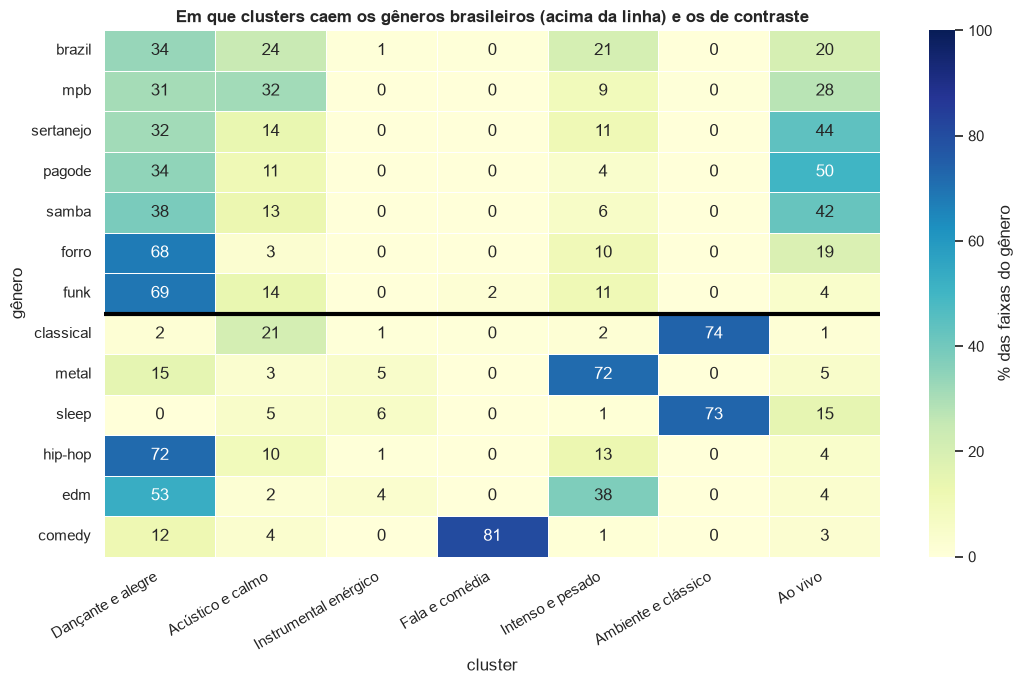

In [42]:
generos_destaque = GENEROS_BR + GENEROS_CONTRASTE
tabela_destaque = (100 * genero_x_cluster.loc[generos_destaque]).rename(columns=NOMES_CLUSTERS)

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(tabela_destaque, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100,
            linewidths=0.5, cbar_kws={"label": "% das faixas do gênero"}, ax=ax)
ax.axhline(len(GENEROS_BR), color="black", linewidth=3)
ax.set(title="Em que clusters caem os gêneros brasileiros (acima da linha) e os de contraste",
       xlabel="cluster", ylabel="gênero")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Os contrastes confirmam a leitura dos grupos:** classical (74%) e sleep (73%) caem em
*Ambiente e clássico*, metal (72%) em *Intenso e pesado*, comedy (81%) em *Fala e comédia* e
hip-hop (72%) em *Dançante e alegre*. O edm se divide entre *Dançante* (53%) e *Intenso* (38%).

**A música brasileira se divide em três perfis:**

1. **Dançante**: **forró (68%)** e **funk (69%)** caem quase todos em *Dançante e alegre*.
2. **Espalhada**: **mpb** se divide quase igualmente entre *Acústico e calmo* (32%), *Dançante*
   (31%) e *Ao vivo* (28%); **brazil** se espalha por quatro grupos (34%, 24%, 21% e 20%).
3. **Ao vivo**: **pagode (50%)**, **sertanejo (44%)** e **samba (42%)** têm o *Ao vivo* como
   grupo principal. Entre os contrastes, o que mais aparece nesse grupo é o sleep, com 15%.

Por que tanta música brasileira no grupo *Ao vivo*? Uma hipótese é o peso das **gravações ao
vivo** nesses gêneros: álbuns e DVDs "Ao Vivo" são muito comuns no pagode, no sertanejo e no samba.
Dá para testar a hipótese com os próprios dados: que fração das faixas brasileiras tem "ao vivo",
"en vivo" ou "live" no nome da faixa ou do álbum, dentro e fora desse grupo?

In [43]:
cluster_ao_vivo = next(c for c, nome in NOMES_CLUSTERS.items() if nome == "Ao vivo")
padrao_ao_vivo = r"ao vivo|en vivo|\blive\b"
marcada_ao_vivo = (
    df_pares["track_name"].str.contains(padrao_ao_vivo, case=False, regex=True)
    | df_pares["album_name"].str.contains(padrao_ao_vivo, case=False, regex=True)
)
eh_br = df_pares["track_genre"].isin(GENEROS_BR)
grupo = np.where(df_pares["cluster"] == cluster_ao_vivo, "no cluster Ao vivo", "nos outros clusters")

ao_vivo_br = (df_pares[eh_br].assign(marcada=marcada_ao_vivo[eh_br], grupo=grupo[eh_br])
              .pivot_table(index="track_genre", columns="grupo", values="marcada", aggfunc="mean"))
print("% das faixas com 'ao vivo' / 'en vivo' / 'live' no nome da faixa ou do álbum")
(100 * ao_vivo_br).round(0)

% das faixas com 'ao vivo' / 'en vivo' / 'live' no nome da faixa ou do álbum


grupo,no cluster Ao vivo,nos outros clusters
track_genre,,
brazil,66.0,12.0
forro,55.0,19.0
funk,42.0,2.0
mpb,76.0,5.0
pagode,89.0,35.0
samba,80.0,14.0
sertanejo,88.0,36.0


Os dados apoiam a hipótese. Em **todos** os gêneros brasileiros, as faixas do grupo *Ao vivo* trazem a
marca de gravação ao vivo no nome muito mais vezes que as dos outros grupos: **89% contra 35%** no
pagode, **88% contra 36%** no sertanejo, **80% contra 14%** no samba e **76% contra 5%** na mpb.

O K-Means não "sabe" o nome de nenhuma faixa: ele chegou a esse grupo só pela feature `liveness`
(a estimativa do Spotify de presença de plateia no áudio). Isso também mostra um limite do agrupamento: esse grupo reflete
**como a música foi gravada**, e não o estilo. Voltamos a isso na V.4.

**Atenção ao rótulo `funk`.** No dataset, `funk` mistura o funk norte-americano (anos 1960–70) com
o funk brasileiro, que são estilos muito diferentes. Os artistas mais frequentes do rótulo
mostram isso:

In [44]:
artistas_funk = (df_pares.loc[df_pares["track_genre"] == "funk", "artists"]
                 .str.split(";").str[0].value_counts().head(12))
artistas_funk.rename_axis("artista principal").to_frame("faixas no rótulo funk")

,faixas no rótulo funk
artista principal,
Stevie Wonder,85
Clean Bandit,47
Red Hot Chili Peppers,40
Anitta,35
MC Hariel,27
Snoop Dogg,24
Mc Kevin,22
The Temptations,22
The Supremes,21


A lista junta Stevie Wonder, The Temptations, James Brown e Red Hot Chili Peppers (funk
norte-americano) com Anitta, MC Hariel, Mc Kevin e Xamã (funk brasileiro). Por isso, os 69% do
`funk` em *Dançante e alegre* **não** podem ser lidos como um resultado só do funk brasileiro:
os dois funks são dançantes, e o rótulo da fonte não permite separá-los.

#### 🧪 Experimente: gêneros à escolha

Onde caem outros gêneros? Troque a lista `GENEROS_EXTRA` por gêneros de sua escolha e rode de
novo. Se um nome não existir no dataset, a célula avisa e lista todos os 114 gêneros disponíveis.

Ideias: `"k-pop"`, `"j-pop"`, `"rock"`, `"blues"`, `"country"`, `"opera"`, `"disney"`,
`"study"`, `"sad"`, `"party"`. O que você espera de `"sad"` e `"party"`? Os grupos concordam?

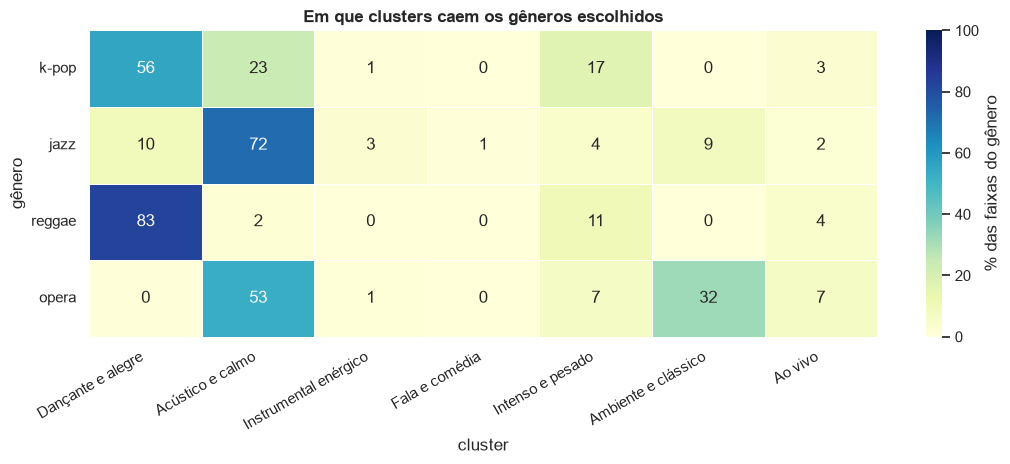

In [45]:
GENEROS_EXTRA = ["k-pop", "jazz", "reggae", "opera"]  # ✏️ troque pelos gêneros que quiser

nao_encontrados = [g for g in GENEROS_EXTRA if g not in genero_x_cluster.index]
if nao_encontrados:
    print(f"Não encontrados: {nao_encontrados}")
    print("Gêneros disponíveis:", ", ".join(genero_x_cluster.index))
encontrados = [g for g in GENEROS_EXTRA if g in genero_x_cluster.index]

tabela_extra = (100 * genero_x_cluster.loc[encontrados]).rename(columns=NOMES_CLUSTERS)
fig, ax = plt.subplots(figsize=(11, 2 + 0.7 * len(encontrados)))
sns.heatmap(tabela_extra, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100,
            linewidths=0.5, cbar_kws={"label": "% das faixas do gênero"}, ax=ax)
ax.set(title="Em que clusters caem os gêneros escolhidos", xlabel="cluster", ylabel="gênero")
ax.tick_params(axis="y", rotation=0)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Com a lista original: **reggae** (83%) cai em *Dançante e alegre*, **jazz** (72%) em *Acústico e
calmo* e **k-pop** se divide entre *Dançante* (56%), *Acústico* (23%) e *Intenso* (17%). A
**opera** se divide entre *Acústico e calmo* (53%) e *Ambiente e clássico* (32%). Faz sentido: é
acústica e calma, mas tem voz, o que a afasta do grupo instrumental.

### V.4 Limitações e melhorias

O K-Means encontrou grupos que fazem sentido, mas ele tem limitações, e todas apareceram nesta
aula:

1. **k precisa ser escolhido antes, e a escolha foi ambígua.** O cotovelo não teve um joelho
   nítido (IV.1), e só a combinação com a silhueta e a interpretabilidade levou a k = 7. Outra
   pessoa, pesando os critérios de outro jeito, poderia defender k = 5 ou 6.
2. **Os grupos se sobrepõem.** A silhueta de k = 7 é **0,196**, numa escala que vai até 1: muitas
   faixas ficam na fronteira entre dois grupos (uma música pode ser dançante *e* intensa). O K-Means
   obriga cada faixa a pertencer a **um único** grupo, sem dizer "60% dançante, 40% ao vivo".
3. **O K-Means supõe grupos "redondos" e de dispersão parecida.** Ele atribui cada ponto ao
   centroide mais próximo, o que funciona melhor quando os grupos são esféricos e têm mais ou menos
   o mesmo "raio" (a mesma dispersão em todas as direções). Aqui o cluster 3 (Fala e comédia) é bem
   mais espalhado que os outros: na IV.3 ele ocupa quase toda a altura do eixo "ao vivo". Grupos
   alongados ou de formato irregular como esse acabam cortados de forma artificial.
4. **É sensível à escala e a valores extremos.** Sem padronização, os 7 grupos viraram 7 faixas de
   andamento, com ARI de 0,039 em relação ao modelo padronizado (IV.4). E como o centroide é uma
   **média**, faixas extremas (como as de `speechiness` perto de 1) puxam os centroides.
5. **Gênero não é som.** O mesmo gênero se espalha por vários grupos (`brazil` em quatro) e o
   rótulo `funk` mistura dois estilos diferentes (V.3). A comparação com gêneros ajuda a
   interpretar, mas não é um "gabarito".
6. **As features são estimativas e nem todas descrevem estilo.** Os números do Spotify vêm de um
   algoritmo (o `grindcore`, com vocais gritados, caiu no grupo instrumental), e `liveness` mede a
   **gravação** (plateia), não o estilo: o grupo *Ao vivo* junta pagode, samba e sertanejo porque
   muitas faixas foram gravadas ao vivo.

**Como melhorar.** Duas ideias atacam diretamente essas limitações:

- **Outros algoritmos de agrupamento.** O **GMM** (*Gaussian Mixture Models*) dá a cada faixa uma
  **probabilidade** de pertencer a cada grupo, o que lida melhor com a sobreposição (limitação 2) e
  com grupos alongados (limitação 3). O **DBSCAN** não pede k e separa pontos isolados como
  "ruído", o que trataria as faixas de fala e os valores extremos (limitações 1 e 4).
- **Treinar de novo sem `liveness`**, para que os grupos reflitam só o estilo, e não a forma de
  gravação (limitação 6), e ver para onde vão o pagode, o samba e o sertanejo.

> **Respondendo à pergunta da aula.** Existem pelo menos **sete perfis de som** nas músicas do
> Spotify: dançante e alegre, acústico e calmo, instrumental enérgico, fala e comédia, intenso e
> pesado, ambiente e clássico, e ao vivo. A música brasileira não forma um grupo próprio: o forró e o
> funk são dançantes, a mpb se divide entre o acústico, o dançante e o ao vivo, e o pagode, o samba e
> o sertanejo se destacam no grupo *Ao vivo*, um retrato de como essas músicas costumam ser
> gravadas.

## Referências

Ao lado de cada referência está a parte da aula em que ela é usada.

**Disciplina**

1. ZANETTI, Humberto. *Projeto final: uso de algoritmo K-Means em aplicações de Ciência de Dados*.
   Enunciado da disciplina ICD-004 Análise de Algoritmos. Jundiaí: Fatec Jundiaí, 2026.
   Define as cinco seções e os critérios de avaliação (estrutura da aula inteira).
2. CORMEN, Thomas H. et al. *Algoritmos: teoria e prática*. 3. ed. Rio de Janeiro: Elsevier, 2012.
   Notação assintótica e análise de custo (I.4).

**O algoritmo e as métricas**

3. LLOYD, Stuart P. Least squares quantization in PCM. *IEEE Transactions on Information Theory*,
   v. 28, n. 2, p. 129–137, 1982. O algoritmo de atribuir e atualizar implementado do zero (I.3).
4. MACQUEEN, James. Some methods for classification and analysis of multivariate observations.
   In: *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*,
   v. 1, p. 281–297, 1967. Origem do nome "K-Means" (I.3).
5. ARTHUR, David; VASSILVITSKII, Sergei. k-means++: the advantages of careful seeding. In:
   *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms (SODA)*,
   p. 1027–1035, 2007. Inicialização k-means++ e o problema dos mínimos locais (I.3 e II.2).
6. THORNDIKE, Robert L. Who belongs in the family? *Psychometrika*, v. 18, n. 4, p. 267–276, 1953.
   Ideia do Método do Cotovelo (I.5 e IV.1).
7. ROUSSEEUW, Peter J. Silhouettes: a graphical aid to the interpretation and validation of
   cluster analysis. *Journal of Computational and Applied Mathematics*, v. 20, p. 53–65, 1987.
   Coeficiente de silhueta (I.5 e IV.1).
8. HUBERT, Lawrence; ARABIE, Phipps. Comparing partitions. *Journal of Classification*, v. 2,
   n. 1, p. 193–218, 1985. Índice de Rand ajustado (ARI), usado para comparar a implementação do
   zero com o scikit-learn (I.3).

**Ferramentas**

9. PEDREGOSA, Fabian et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning
   Research*, v. 12, p. 2825–2830, 2011 (II).
10. SCIKIT-LEARN. Documentação oficial (II.2, III.5 e IV):
    [Clustering: K-Means](https://scikit-learn.org/stable/modules/clustering.html#k-means),
    [`KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html),
    [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
    [`silhouette_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
    e [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
11. GÉRON, Aurélien. *Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras & TensorFlow*. 2. ed.
    Rio de Janeiro: Alta Books, 2021. Capítulo 9, aprendizado não supervisionado e K-Means (I e II).

**Dados**

12. PANDYA, Maharshi. *Spotify Tracks Dataset*. Hugging Face. Licença BSD. Acesso em: 22 nov. 2026. Disponível em:
    [huggingface.co/datasets/maharshipandya/spotify-tracks-dataset](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset).
    O conjunto de dados da aula (III a V). Cópia de reserva em
    [`data/`](https://github.com/DataScience-Fatec-Projects/kmeans-musicas-spotify/tree/main/data).
13. SPOTIFY. *Web API Reference: Get Track's Audio Features*. Acesso em: 22 nov. 2026. Disponível em:
    [developer.spotify.com](https://developer.spotify.com/documentation/web-api/reference/get-audio-features).
    Definição de cada característica de áudio do dicionário de variáveis (III.2).